**Consistency**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize, linear_sum_assignment
from scipy.stats import chi2
from tqdm import tqdm
import warnings

warnings.filterwarnings("ignore", category=RuntimeWarning)
np.seterr(all="ignore")

# ============================================================
# Helpers
# ============================================================
def _normalize_w(w, eps=1e-9):
    w = np.maximum(np.asarray(w, dtype=float), eps)
    return w / (w.sum() + eps)

def _as_dim_array(x, d):
    x = np.asarray(x, dtype=float)
    if x.ndim == 0:
        return np.full(d, float(x))
    assert x.size == d, "proposal_std must be scalar or length-d"
    return x

def _make_true_centers(d, c, radius=10.0, rng=None):
    """
    Construct c well-separated centers in R^d.
    For d==2: place on a circle; else: random on a sphere scaled by radius.
    """
    rng = np.random.RandomState(None if rng is None else rng)
    if d == 2:
        angles = np.linspace(0, 2*np.pi, c, endpoint=False)
        centers = np.stack([radius*np.cos(angles), radius*np.sin(angles)], axis=1)
    else:
        X = rng.randn(c, d)
        X /= (np.linalg.norm(X, axis=1, keepdims=True) + 1e-12)
        centers = radius * X
    return centers

# ============================================================
# 1) Target density (any d, any c)
# ============================================================
def target_density_ccluster(x, sigma, centers, m, w, epsilon=1e-8):
    """
    Unnormalized target density:
    h(x) = exp( -1 / ( sigma^2 * [sum_j w_j ||x-v_j||^{-2/(m-1)}]^{m-1} ) )
    x: (N,d) array
    """
    w = _normalize_w(w)
    diffs = x[:, None, :] - centers[None, :, :]
    dnorm = np.linalg.norm(diffs, axis=2) + epsilon  # (N, c)
    dist_power = w[None, :] * (dnorm ** (-2.0 / (m - 1.0)))
    s = np.sum(dist_power, axis=1)
    denom = s ** (m - 1.0)
    exponent = -1.0 / (sigma**2 * denom + epsilon)
    return np.exp(exponent)

# ============================================================
# 1B) Metropolis–Hastings sampler (any d)
# ============================================================
def metropolis_hastings_ccluster(target_density, initial_point, sigma, centers, m, w,
                                 iterations=20000, proposal_std=1.0, burn_in=0.1, seed=42):
    rng = np.random.RandomState(seed)
    d = initial_point.size
    proposal_std = _as_dim_array(proposal_std, d)

    samples = np.zeros((iterations, d), dtype=float)
    samples[0] = initial_point
    accepted = 0

    current_val = target_density(samples[0].reshape(1, -1), sigma, centers, m, w)[0]
    for i in range(1, iterations):
        current = samples[i - 1]
        proposal = current + rng.randn(d) * proposal_std
        proposal_val = target_density(proposal.reshape(1, -1), sigma, centers, m, w)[0]
        alpha = min(1.0, proposal_val / (current_val + 1e-12))
        if rng.rand() < alpha:
            samples[i] = proposal
            current_val = proposal_val
            accepted += 1
        else:
            samples[i] = current

    acceptance_rate = accepted / (iterations - 1)
    burn_in_steps = int(iterations * burn_in)
    return samples[burn_in_steps:], acceptance_rate

# ============================================================
# 1C) Mixture-scale MH (mode hopping)
# ============================================================
def metropolis_hastings_ccluster_mixture_moves(
    target_density, initial_point, sigma, centers, m, w,
    iterations=20000, proposal_std_small=1.0, proposal_std_big=None, p_big=0.10,
    burn_in=0.1, seed=42
):
    """
    Random-walk MH with mixture-of-scales proposals:
    with prob p_big, use a large step; else use a small step.
    """
    rng = np.random.RandomState(seed)
    d = initial_point.size
    small = _as_dim_array(proposal_std_small, d)

    if proposal_std_big is None:
        if centers is not None and centers.shape[0] > 1:
            D = np.linalg.norm(centers[:, None, :] - centers[None, :, :], axis=2)
            tri = D[np.triu_indices_from(D, k=1)]
            proposal_std_big = float(np.median(tri)) if tri.size else 10.0
        else:
            proposal_std_big = 10.0
    big = _as_dim_array(proposal_std_big, d)

    samples = np.zeros((iterations, d), dtype=float)
    samples[0] = initial_point
    accepted = 0

    current_val = target_density(samples[0].reshape(1, -1), sigma, centers, m, w)[0]
    for i in range(1, iterations):
        current = samples[i - 1]
        step = rng.randn(d) * (big if rng.rand() < p_big else small)
        proposal = current + step
        proposal_val = target_density(proposal.reshape(1, -1), sigma, centers, m, w)[0]
        alpha = min(1.0, proposal_val / (current_val + 1e-12))
        if rng.rand() < alpha:
            samples[i] = proposal
            current_val = proposal_val
            accepted += 1
        else:
            samples[i] = current

    burn_in_steps = int(iterations * burn_in)
    acc = accepted / (iterations - 1)
    return samples[burn_in_steps:], acc

# ============================================================
# 2) Memberships (any d, any c)
# ============================================================
def update_membership_c(data, centers, w, m, epsilon=1e-8):
    """
    U_{ij} ∝ (w_j * ||x_i - v_j||^2)^(-1/(m-1))
    Implemented as w_j * ||x_i - v_j||^{-2/(m-1)} then normalize across j.
    """
    w = _normalize_w(w)
    diffs = data[:, None, :] - centers[None, :, :]
    dnorm = np.linalg.norm(diffs, axis=2) + epsilon  # (N, c)
    dist_power = w[None, :] * (dnorm ** (-2.0 / (m - 1.0)))
    denom = np.sum(dist_power, axis=1, keepdims=True) + epsilon
    return dist_power / denom

# ============================================================
# 3) Centroids (M-step A) (any d, any c)  **FIXED: no extra w[j] factor**
# ============================================================
def update_centroids_c(data, U, w, m, epsilon=1e-8):
    c = U.shape[1]
    _, dim = data.shape
    centers_new = np.zeros((c, dim), dtype=float)
    for j in range(c):
        u_pow = (U[:, j] ** m)           # <-- no * w[j]; membership already includes w
        numerator = (u_pow[:, None] * data).sum(axis=0)
        denominator = np.sum(u_pow) + epsilon
        centers_new[j] = numerator / denominator
    return centers_new

# ============================================================
# 4A) Full NLL (monitoring / optimization target)
# ============================================================
def partial_negative_log_likelihood_full(params, data, proposal_samples, proposal_weights, m, c, epsilon=1e-8):
    """
    params = [sigma, centers_flat(c*dim), w(c)]
    Returns N * log(Z_est) + sum_i 1/(sigma^2 * S_i^{m-1})
    """
    params = np.array(params, dtype=float)
    sigma = float(params[0])
    N, dim = data.shape
    centers = params[1:1 + c * dim].reshape((c, dim))
    w = _normalize_w(params[1 + c * dim: 1 + c * dim + c])

    diffs = data[:, None, :] - centers[None, :, :]
    dnorm = np.linalg.norm(diffs, axis=2) + epsilon
    dist_power = w[None, :] * (dnorm ** (-2.0 / (m - 1.0)))
    denom_data = (np.sum(dist_power, axis=1) + epsilon) ** (m - 1.0)
    energy = np.sum(1.0 / (sigma**2 * denom_data + epsilon))

    f_x = target_density_ccluster(proposal_samples, sigma, centers, m, w, epsilon=epsilon)
    ratio = f_x / (proposal_weights + 1e-12)
    Z_est = np.mean(ratio) + epsilon

    return N * np.log(Z_est) + energy

# ============================================================
# 4B) NLL with centers fixed — optimize σ, w (any d, any c)
# ============================================================
def partial_negative_log_likelihood_fixed_centers(params_sw, data, centers_fixed,
                                                  proposal_samples, proposal_weights, m, c, epsilon=1e-8):
    params_sw = np.array(params_sw, dtype=float)
    sigma = float(params_sw[0])
    w = _normalize_w(params_sw[1:1 + c])

    N = data.shape[0]
    diffs = data[:, None, :] - centers_fixed[None, :, :]
    dnorm = np.linalg.norm(diffs, axis=2) + epsilon
    dist_power = w[None, :] * (dnorm ** (-2.0 / (m - 1.0)))
    denom_data = (np.sum(dist_power, axis=1) + epsilon) ** (m - 1.0)
    energy = np.sum(1.0 / (sigma**2 * denom_data + epsilon))

    f_x = target_density_ccluster(proposal_samples, sigma, centers_fixed, m, w, epsilon=epsilon)
    ratio = f_x / (proposal_weights + 1e-12)
    Z_est = np.mean(ratio) + epsilon

    return N * np.log(Z_est) + energy

# ============================================================
# 5) EM-like fuzzy clustering (any d, any c)
# ============================================================
def em_like_fuzzy_clustering_c(data, proposal_samples, proposal_weights, m, c,
                               initial_sigma=1.0, initial_centers=None, initial_w=None,
                               max_iter=30, tol=1e-5, random_state=42, centroid_damping=1.0,
                               verbose=True):
    """
    Alternates:
      (E) memberships U
      (M-A) centers
      (M-B) (sigma, w) with centers fixed
    Monitors full NLL.
    """
    rng = np.random.RandomState(random_state)
    N, dim = data.shape

    sigma = float(initial_sigma)
    if initial_centers is None:
        idx = rng.choice(N, c, replace=False)
        centers = data[idx].copy()
    else:
        centers = np.asarray(initial_centers, dtype=float).reshape((c, dim))

    if initial_w is None:
        w = np.ones(c) / c
    else:
        w = _normalize_w(initial_w)

    old_nll = None

    for iteration in range(max_iter):
        # E-step
        U = update_membership_c(data, centers, w, m)

        # M-step A: centers
        centers_new = update_centroids_c(data, U, w, m)
        centers = centroid_damping * centers_new + (1.0 - centroid_damping) * centers

        # M-step B: sigma, w (centers fixed)
        x0_sw = [sigma] + list(w)
        bnds_sw = [(1e-5, 100.0)] + [(1e-6, 1.0)] * c

        def objective_sw(params_sw):
            return partial_negative_log_likelihood_fixed_centers(
                params_sw, data, centers, proposal_samples, proposal_weights, m, c
            )

        res = minimize(objective_sw, x0_sw, method="L-BFGS-B", bounds=bnds_sw)
        if res.success:
            p_opt = np.array(res.x, dtype=float)
            sigma = float(p_opt[0])
            w = _normalize_w(p_opt[1:1 + c])

        # Full NLL
        full_params = [sigma] + list(centers.flatten()) + list(w)
        new_nll = partial_negative_log_likelihood_full(
            full_params, data, proposal_samples, proposal_weights, m, c
        )

        if verbose:
            if old_nll is None:
                print(f"Iteration {iteration + 1}/{max_iter}  NLL={new_nll:.6f}  Δ=—")
            else:
                improvement = abs(old_nll - new_nll)
                print(f"Iteration {iteration + 1}/{max_iter}  NLL={new_nll:.6f}  Δ={improvement:.2e}")

        if (old_nll is not None) and (abs(old_nll - new_nll) < tol):
            old_nll = new_nll
            break
        old_nll = new_nll

    U_final = update_membership_c(data, centers, w, m)
    return {"c": c, "m": m, "sigma": sigma, "centers": centers, "w": w, "U": U_final, "NLL": old_nll}

# ============================================================
# 6) GMM proposal (any d)
# ============================================================
def generate_proposal_samples_gmm_c(data, num_samples=5000, n_components=3, random_state=42):
    from sklearn.mixture import GaussianMixture
    gmm = GaussianMixture(n_components=n_components, covariance_type='full', random_state=random_state)
    gmm.fit(data)
    samples_IS, _ = gmm.sample(num_samples)
    proposal_pdf = np.exp(gmm.score_samples(samples_IS))
    return samples_IS, proposal_pdf, gmm

# ============================================================
# 7) Profile likelihood for one parameter (any d, any c)
# ============================================================
def insert_fixed_param(mle_params, param_idx, fixed_value, rest_params):
    new_params, r = [], 0
    for i in range(len(mle_params)):
        if i == param_idx:
            new_params.append(fixed_value)
        else:
            new_params.append(rest_params[r])
            r += 1
    return np.array(new_params, dtype=float)

def profile_likelihood_param(mle_params, param_idx, data, proposal_samples, proposal_weights, m, c,
                             grid_points=50, range_factor=0.2, alpha=0.05):
    N, dim = data.shape
    p0 = float(mle_params[param_idx])
    span = range_factor * (abs(p0) + 1e-3)
    grid = np.linspace(p0 - span, p0 + span, grid_points)
    profile_nll = []
    threshold = 0.5 * chi2.ppf(1 - alpha, df=1)

    full_bounds = [(1e-5, 100.0)] + [(None, None)] * (c * dim) + [(1e-6, 1.0)] * c
    rest_bounds = [full_bounds[i] for i in range(len(full_bounds)) if i != param_idx]
    rest_initial = np.delete(mle_params, param_idx)

    for candidate_val in tqdm(grid, desc=f"Profiling idx {param_idx}"):
        def objective_rest(rest_params):
            candidate = insert_fixed_param(mle_params, param_idx, candidate_val, rest_params)
            return partial_negative_log_likelihood_full(
                candidate, data, proposal_samples, proposal_weights, m, c
            )
        res = minimize(objective_rest, rest_initial, bounds=rest_bounds, method="L-BFGS-B")
        if res.success:
            candidate_params = insert_fixed_param(mle_params, param_idx, candidate_val, res.x)
            nll_val = partial_negative_log_likelihood_full(
                candidate_params, data, proposal_samples, proposal_weights, m, c
            )
            profile_nll.append(nll_val)
            rest_initial = res.x.copy()
        else:
            profile_nll.append(np.nan)

    return grid, np.array(profile_nll), threshold

# ============================================================
# 8) Plot: 2D projection (first two coordinates) with centers
# ============================================================
def plot_first_two_coords_with_centers(data, centers_true=None, centers_hat=None, memberships=None,
                                       max_points=8000, title="2D projection (first two coords)"):
    """
    Scatter plot of data[:, :2] and overlay true vs estimated centers (first two coords).
    If memberships (N, c) is provided, color by argmax label; else use gray.
    """
    N = data.shape[0]
    idx = np.arange(N)
    if N > max_points:
        rng = np.random.RandomState(123)
        idx = rng.choice(N, size=max_points, replace=False)
    xy = data[idx, :2]

    plt.figure(figsize=(6.5, 5.5))
    if memberships is not None:
        labels = np.argmax(memberships[idx], axis=1)
        plt.scatter(xy[:, 0], xy[:, 1], c=labels, s=5, alpha=0.35,
                    cmap='tab10', label="Data (colored by hard label)")
    else:
        plt.scatter(xy[:, 0], xy[:, 1], s=5, alpha=0.3, color='gray', label="Data")

    # True centers (projected)
    if centers_true is not None:
        plt.scatter(centers_true[:, 0], centers_true[:, 1],
                    marker='X', s=140, edgecolor='k', linewidths=0.7,
                    color='none', label="True centers")

    # Estimated centers (projected)
    if centers_hat is not None:
        plt.scatter(centers_hat[:, 0], centers_hat[:, 1],
                    marker='^', s=120, color='red', alpha=0.9, label="Estimated centers")

    plt.title(title)
    plt.xlabel("coord 1")
    plt.ylabel("coord 2")
    plt.legend(loc="best")
    plt.tight_layout()
    plt.show()

# ============================================================
# 9) Alignment & error metrics
# ============================================================
def align_estimates(centers_hat, w_hat, centers_true):
    """
    Align estimated components to the true ones via Hungarian assignment
    using Euclidean center distances as the cost.
    Returns: centers_hat_aligned, w_hat_aligned, perm (perm[j] = true index matched to est j)
    """
    c = centers_true.shape[0]
    cost = np.linalg.norm(
        centers_hat[:, None, :] - centers_true[None, :, :], axis=2
    )
    row_ind, col_ind = linear_sum_assignment(cost)
    order = np.argsort(row_ind)
    perm = col_ind[order]
    centers_aligned = centers_hat[order]
    w_aligned = w_hat[order]
    return centers_aligned, w_aligned, perm

def estimation_errors(centers_hat, w_hat, sigma_hat, centers_true, w_true, sigma_true):
    """
    Label-invariant errors between estimates and truth.
    """
    centers_a, w_a, perm = align_estimates(centers_hat, w_hat, centers_true)

    # center errors (full d-dim)
    diffs = centers_a - centers_true
    per_center_dist = np.linalg.norm(diffs, axis=1)
    center_rmse = np.sqrt(np.mean(np.sum(diffs**2, axis=1)))
    center_mean = per_center_dist.mean()
    center_max = per_center_dist.max()

    # weight errors
    w_true_n = _normalize_w(w_true)
    w_a_n    = _normalize_w(w_a)
    w_l1 = float(np.sum(np.abs(w_a_n - w_true_n)))
    w_l2 = float(np.linalg.norm(w_a_n - w_true_n))

    # sigma error
    sigma_abs = float(abs(float(sigma_hat) - float(sigma_true)))

    # symmetric KL on weights (clipped)
    eps = 1e-12
    p = np.clip(w_true_n, eps, 1.0); p /= p.sum()
    q = np.clip(w_a_n,    eps, 1.0); q /= q.sum()
    kl_pq = float(np.sum(p * (np.log(p) - np.log(q))))
    kl_qp = float(np.sum(q * (np.log(q) - np.log(p))))
    skl   = 0.5 * (kl_pq + kl_qp)

    return {
        "center_rmse": center_rmse,
        "center_mean": center_mean,
        "center_max": center_max,
        "center_component_dists": per_center_dist,
        "w_l1": w_l1,
        "w_l2": w_l2,
        "w_sKL": skl,
        "sigma_abs": sigma_abs,
        "perm": perm,
    }

# ============================================================
# 10) Weighted Xie–Beni (model selection)
# ============================================================
def weighted_xie_beni_index(data, centers, w, U, m, epsilon=1e-8):
    """
    XB_weighted = sum_i sum_j w_j * u_ij^m * ||x_i - v_j||^2 / min_{j!=l} ||v_j - v_l||^2
    """
    w = _normalize_w(w)
    diffs = data[:, None, :] - centers[None, :, :]
    d2 = np.sum(diffs**2, axis=2)  # (N,c)
    num = np.sum(w[None, :] * (U ** m) * d2)
    # min center separation
    c = centers.shape[0]
    if c < 2:
        return np.inf
    D = np.linalg.norm(centers[:, None, :] - centers[None, :, :], axis=2)
    min_sep = np.min(D + np.eye(c) * 1e9)  # ignore diagonal
    denom = (min_sep ** 2) + epsilon
    return float(num / denom)

def select_m_via_nll(data, c, m_grid, is_samples=20000, ic_components=None,
                     fit_iters=50, random_state=1234, centroid_damping=0.9,
                     verbose=False):
    """
    For each m in m_grid:
      - Fit GMM proposal once (per dataset)
      - Run EM-like fit for (sigma, centers, w)
      - Compute train NLL (importance-sampled)
    Return dict with best m and per-m records.
    """
    rng = np.random.RandomState(random_state)
    N, dim = data.shape
    if ic_components is None:
        ic_components = min(max(2, c), 6)

    # Shared proposal across all m
    samples_IS, proposal_pdf, _ = generate_proposal_samples_gmm_c(
        data, num_samples=is_samples, n_components=ic_components, random_state=random_state + 7
    )

    records = []
    best = None

    # Initialize centers from k-means++-like (random subset)
    init_idx = rng.choice(N, c, replace=False)
    init_centers_base = data[init_idx].copy()

    for m in m_grid:
        fit = em_like_fuzzy_clustering_c(
            data=data,
            proposal_samples=samples_IS,
            proposal_weights=proposal_pdf,
            m=float(m),
            c=c,
            initial_sigma=1.0,
            initial_centers=init_centers_base,
            initial_w=None,
            max_iter=fit_iters,
            random_state=random_state + int(1000 * m),
            centroid_damping=centroid_damping,
            verbose=False
        )
        # Re-evaluate full NLL with fitted params (already reported, but recompute to be safe)
        sigma = fit["sigma"]
        centers = fit["centers"]
        w = fit["w"]
        params = [sigma] + list(centers.flatten()) + list(w)
        nll = partial_negative_log_likelihood_full(
            params, data, samples_IS, proposal_pdf, float(m), c
        )
        rec = {"m": float(m), "fit": fit, "trainNLL": float(nll)}
        records.append(rec)
        if verbose:
            print(f"m={m:.3f}  trainNLL={nll:.3f}")
        if best is None or nll < best["trainNLL"]:
            best = rec

    return {"best": best, "records": records}

# ============================================================
# 11) Convenience: pack/unpack parameter vector
# ============================================================
def pack_params(sigma, centers, w):
    """
    Returns flat parameter vector [sigma, centers_flat, w]
    """
    return np.concatenate([[float(sigma)], centers.reshape(-1), _normalize_w(w)])

def unpack_params(params, c, d):
    """
    Given flat params and (c,d), returns (sigma, centers(c,d), w(c))
    """
    sigma = float(params[0])
    centers = np.array(params[1:1+c*d], dtype=float).reshape((c, d))
    w = _normalize_w(np.array(params[1+c*d:1+c*d+c], dtype=float))
    return sigma, centers, w

# ============================================================
# 12) Final joint refinement on full NLL (used inside consistency_study)
# ============================================================
def refine_full_nll_from(sigma, centers, w, data, proposal_samples, proposal_weights, m, c,
                         max_iter=200):
    """
    Run joint L-BFGS-B on the full NLL over [sigma, centers, w]
    starting from (sigma, centers, w).
    """
    N, d = data.shape
    x0 = pack_params(sigma, centers, w)
    bounds = [(1e-5, 100.0)] + [(None, None)] * (c * d) + [(1e-6, 1.0)] * c

    def obj(theta):
        return partial_negative_log_likelihood_full(
            theta, data, proposal_samples, proposal_weights, m, c
        )

    res = minimize(obj, x0, method="L-BFGS-B", bounds=bounds,
                   options={"maxiter": max_iter})
    theta_opt = res.x if res.success else x0
    sigma_opt, centers_opt, w_opt = unpack_params(theta_opt, c, d)
    nll_opt = obj(theta_opt)
    return {"sigma": sigma_opt, "centers": centers_opt, "w": w_opt,
            "success": bool(res.success), "NLL": float(nll_opt)}

# ============================================================
# 13) Consistency study  **NOW: refines EM output with joint GD on full NLL**
# ============================================================
def consistency_study(
    d, c_true, m_true,
    centers_true=None, w_true=None, sigma_true=2.0,
    n_list=(1000, 2000, 5000, 10000, 20000),
    num_reps=5,
    mh_iterations_per_rep=None,   # if None, auto to cover max(n_list)
    mh_use_mixture_moves=True,
    mh_burn_in=0.20,
    is_samples=5000,
    fit_max_iter=60,
    init_near_truth=True,         # start EM near truth to avoid local minima
    init_jitter=0.2,
    centroid_damping=0.9,
    random_seed_base=1234,
    make_plots=True,
    verbose=True,
):
    """
    For each n in n_list, run num_reps fits and record label-invariant errors for
    centers, weights, and sigma. Returns raw errors, summaries, and estimates.

    NEW: After EM-like fitting, we run a final joint L-BFGS-B on the full NLL
    using the EM output as initialization.
    """
    rng = np.random.RandomState(random_seed_base)
    n_list = list(n_list)

    # ----- truth -----
    if centers_true is None:
        centers_true = _make_true_centers(d, c_true, radius=3.5, rng=random_seed_base+11)
    else:
        centers_true = np.asarray(centers_true, dtype=float).reshape((c_true, d))

    if w_true is None:
        w_true = rng.dirichlet(alpha=np.ones(c_true))
    else:
        w_true = _normalize_w(w_true)

    sigma_true = float(sigma_true)

    if verbose:
        print("Truth:")
        print(" centers_true=\n", centers_true)
        print(" w_true(norm)=", w_true)
        print(" sigma_true=", sigma_true)

    max_n = int(np.max(n_list))
    if mh_iterations_per_rep is None:
        # choose enough post-burn-in draws for max_n
        mh_iterations_per_rep = int(np.ceil(max_n / (1.0 - mh_burn_in))) + 2000

    # storage
    errs = {int(n): [] for n in n_list}
    estimates = {int(n): [] for n in n_list}

    # ----- repetitions -----
    for rep in range(num_reps):
        seed = random_seed_base + 1000 + rep
        if verbose:
            print(f"\n[rep {rep+1}/{num_reps}] MH sampling... (iter={mh_iterations_per_rep})")

        # MH sampling from the target
        if mh_use_mixture_moves:
            data_pool, acc_rate = metropolis_hastings_ccluster_mixture_moves(
                target_density=target_density_ccluster,
                initial_point=np.zeros(d),
                sigma=sigma_true,
                centers=centers_true,
                m=m_true,
                w=w_true,
                iterations=mh_iterations_per_rep,
                proposal_std_small=1.0,
                proposal_std_big=None,   # auto
                p_big=0.20,
                burn_in=mh_burn_in,
                seed=seed
            )
        else:
            data_pool, acc_rate = metropolis_hastings_ccluster(
                target_density=target_density_ccluster,
                initial_point=np.zeros(d),
                sigma=sigma_true,
                centers=centers_true,
                m=m_true,
                w=w_true,
                iterations=mh_iterations_per_rep,
                proposal_std=1.0,
                burn_in=mh_burn_in,
                seed=seed
            )
        if verbose:
            print(f" MH acceptance ~ {acc_rate:.3f}  pool_size={data_pool.shape[0]}")

        if data_pool.shape[0] < max_n:
            raise ValueError("Increase mh_iterations_per_rep so pool covers max(n_list).")

        # ----- over sample sizes -----
        for n in n_list:
            n = int(n)
            data = data_pool[:n]

            # IS proposal
            samples_IS, proposal_pdf, _ = generate_proposal_samples_gmm_c(
                data, num_samples=is_samples, n_components=min(max(2, c_true), 6),
                random_state=seed + 77
            )

            # EM init
            if init_near_truth:
                rloc = np.random.RandomState(seed+999)
                init_centers = centers_true + init_jitter * rloc.randn(*centers_true.shape)
                init_sigma = max(1e-2, sigma_true + 0.05*rloc.randn())
                init_w = _normalize_w(w_true + 0.01*rloc.randn(c_true))
            else:
                init_centers = None
                init_sigma = 1.0
                init_w = None

            # (A) EM-like estimator
            fit = em_like_fuzzy_clustering_c(
                data=data,
                proposal_samples=samples_IS,
                proposal_weights=proposal_pdf,
                m=m_true, c=c_true,
                initial_sigma=init_sigma,
                initial_centers=init_centers,
                initial_w=init_w,
                max_iter=fit_max_iter,
                random_state=seed + 12345,
                centroid_damping=centroid_damping,
                verbose=False
            )

            # (B) FINAL JOINT REFINEMENT on full NLL starting from EM output
            ref = refine_full_nll_from(
                sigma=fit["sigma"], centers=fit["centers"], w=fit["w"],
                data=data, proposal_samples=samples_IS, proposal_weights=proposal_pdf,
                m=m_true, c=c_true, max_iter=200
            )
            # Use refined params going forward
            sigma_hat = ref["sigma"]
            centers_hat = ref["centers"]
            w_hat = ref["w"]
            nll_hat = ref["NLL"]

            # align & errors (with refined params)
            e = estimation_errors(
                centers_hat=centers_hat, w_hat=w_hat, sigma_hat=sigma_hat,
                centers_true=centers_true, w_true=w_true, sigma_true=sigma_true
            )
            e["NLL"] = float(nll_hat)
            errs[n].append(e)

            centers_a, w_a, perm = align_estimates(centers_hat, w_hat, centers_true)
            estimates[n].append({
                "sigma_hat": float(sigma_hat),
                "w_hat_aligned": w_a.copy(),
                "centers_hat_aligned": centers_a.copy(),
                "perm": perm.copy()
            })

    # ----- aggregate -----
    def agg(xs, key):
        arr = np.array([x[key] for x in xs], dtype=float)
        return float(np.mean(arr)), float(np.std(arr))

    summary = {}
    for n in n_list:
        xs = errs[int(n)]
        summary[int(n)] = {
            "center_rmse_mean_std": agg(xs, "center_rmse"),
            "center_mean_mean_std": agg(xs, "center_mean"),
            "center_max_mean_std":  agg(xs, "center_max"),
            "w_l1_mean_std":        agg(xs, "w_l1"),
            "w_l2_mean_std":        agg(xs, "w_l2"),
            "w_sKL_mean_std":       agg(xs, "w_sKL"),
            "sigma_abs_mean_std":   agg(xs, "sigma_abs"),
            "NLL_mean_std":         agg(xs, "NLL"),
        }

    # ----- quick plots (optional) -----
    if make_plots:
        ns = np.array(list(map(int, n_list)), dtype=float)

        def plot_curve(y_key, ylabel):
            means = np.array([summary[int(n)][y_key][0] for n in n_list])
            plt.figure(figsize=(6.2,4.6))
            plt.loglog(ns, means, marker='o', label=ylabel)
            ref = means[0] * np.sqrt(ns[0] / ns)  # 1/sqrt(n) guide
            plt.loglog(ns, ref, linestyle='--', label='~1/sqrt(n)')
            plt.xlabel("n (log)")
            plt.ylabel(ylabel)
            plt.title(f"{ylabel} vs n")
            plt.legend()
            plt.tight_layout()
            plt.show()

        plot_curve("center_rmse_mean_std", "Center RMSE")
        plot_curve("w_l1_mean_std",       "Weight L1 error")
        plot_curve("sigma_abs_mean_std",  "Sigma abs error")

    # ----- print compact table -----
    print("\n=== Consistency summary (mean ± std over reps) ===")
    for n in n_list:
        s = summary[int(n)]
        print(f"n={int(n):>6d} | "
              f"center_RMSE {s['center_rmse_mean_std'][0]:.4f}±{s['center_rmse_mean_std'][1]:.4f} | "
              f"w_L1 {s['w_l1_mean_std'][0]:.4f}±{s['w_l1_mean_std'][1]:.4f} | "
              f"sigma_abs {s['sigma_abs_mean_std'][0]:.4f}±{s['sigma_abs_mean_std'][1]:.4f}")

    return {
        "errors": errs,
        "summary": summary,
        "estimates": estimates,
        "truth": {"centers_true": centers_true, "w_true": w_true, "sigma_true": sigma_true}
    }


Truth:
 centers_true=
 [[  0.    0.    0. ]
 [ 20.    0.   -1. ]
 [-20.    2.5   1. ]]
 w_true(norm)= [0.7 0.1 0.2]
 sigma_true= 2.0

[rep 1/50] MH sampling... (iter=127000)
 MH acceptance ~ 0.241  pool_size=101600

[rep 2/50] MH sampling... (iter=127000)
 MH acceptance ~ 0.411  pool_size=101600

[rep 3/50] MH sampling... (iter=127000)
 MH acceptance ~ 0.414  pool_size=101600

[rep 4/50] MH sampling... (iter=127000)
 MH acceptance ~ 0.410  pool_size=101600

[rep 5/50] MH sampling... (iter=127000)
 MH acceptance ~ 0.415  pool_size=101600

[rep 6/50] MH sampling... (iter=127000)
 MH acceptance ~ 0.387  pool_size=101600

[rep 7/50] MH sampling... (iter=127000)
 MH acceptance ~ 0.405  pool_size=101600

[rep 8/50] MH sampling... (iter=127000)
 MH acceptance ~ 0.416  pool_size=101600

[rep 9/50] MH sampling... (iter=127000)
 MH acceptance ~ 0.387  pool_size=101600

[rep 10/50] MH sampling... (iter=127000)
 MH acceptance ~ 0.350  pool_size=101600

[rep 11/50] MH sampling... (iter=127000)
 MH 

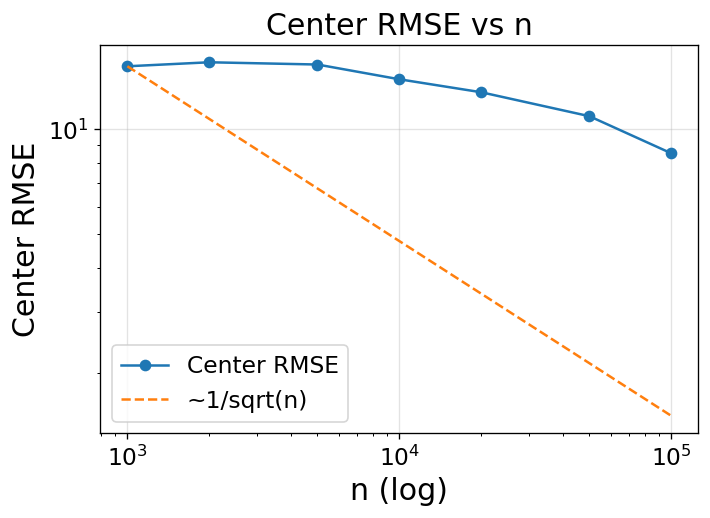

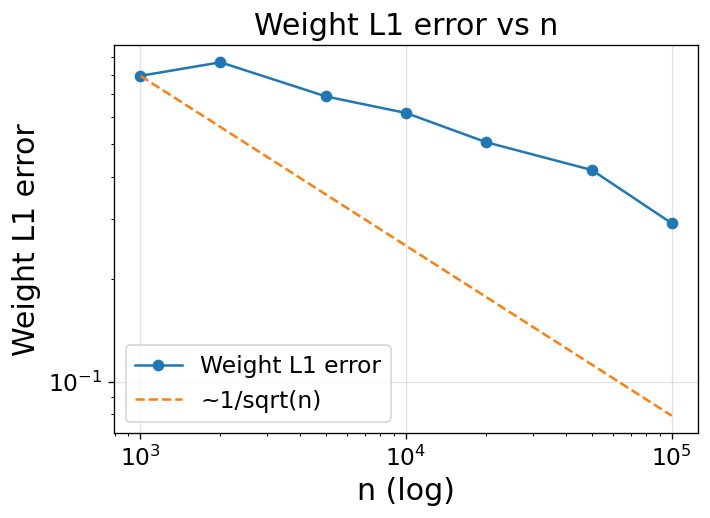

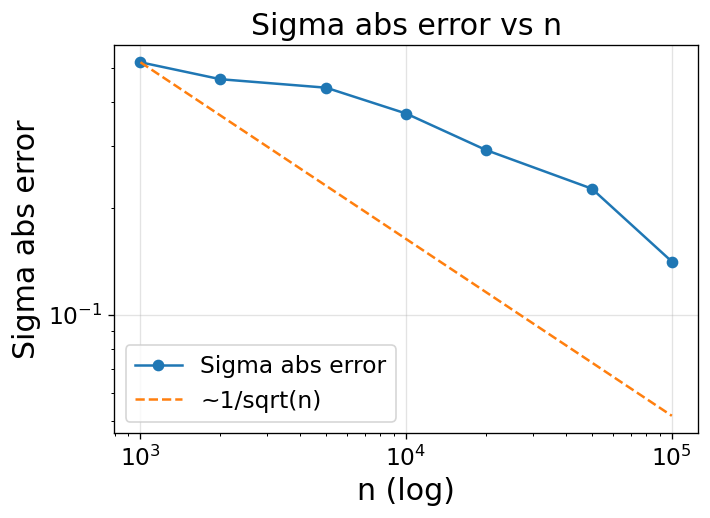


=== Consistency summary (mean ± std over reps) ===
n=  1000 | center_RMSE 15.1267±1.8839 | w_L1 0.7930±0.5044 | sigma_abs 0.5175±0.3261
n=  2000 | center_RMSE 15.5317±2.6772 | w_L1 0.8694±0.5069 | sigma_abs 0.4634±0.3233
n=  5000 | center_RMSE 15.3040±2.9743 | w_L1 0.6895±0.3681 | sigma_abs 0.4385±0.3058
n= 10000 | center_RMSE 13.8865±3.3562 | w_L1 0.6166±0.3505 | sigma_abs 0.3705±0.2804
n= 20000 | center_RMSE 12.7494±2.9604 | w_L1 0.5060±0.2399 | sigma_abs 0.2921±0.1781
n= 50000 | center_RMSE 10.8879±4.7763 | w_L1 0.4191±0.2624 | sigma_abs 0.2272±0.1941
n=100000 | center_RMSE 8.5283±4.9420 | w_L1 0.2920±0.1585 | sigma_abs 0.1413±0.0959


In [ ]:
# ========= Example driver (you choose truth) ==============================
if __name__ == "__main__":
    d = 3
    c_true = 3
    m_true = 2.0

    # Choose your truth explicitly (yes, you can!)
    centers_true = np.array([
        [ 0.0,  0.0, 0.0],
        [20.0,  0.0,-1.0],
        [-20.0, 2.5, 1.0],
    ], dtype=float)
    w_true = np.array([0.70, 0.10, 0.20], dtype=float)   # will be normalized
    sigma_true = 2.0

    results = consistency_study(
        d=d, c_true=c_true, m_true=m_true,
        centers_true=centers_true, w_true=w_true, sigma_true=sigma_true,
        n_list=(1000, 2000, 5000, 10000, 20000, 50000, 100000),   # sample sizes to test
        num_reps=50,                         # repetitions per n
        mh_iterations_per_rep=None,         # auto-compute to cover max(n)
        mh_use_mixture_moves=True,          # better mixing between modes
        is_samples=5000,
        fit_max_iter=40,
        init_near_truth=True,               # initialize EM near truth (stabilizes)
        init_jitter=0.3,
        centroid_damping=0.9,
        random_seed_base=2025,
        make_plots=True,
        verbose=True,
    )

    # Access aligned per-rep estimates if you want to save them:
    # e.g., results["estimates"][n][rep_idx]["w_hat_aligned"], etc.


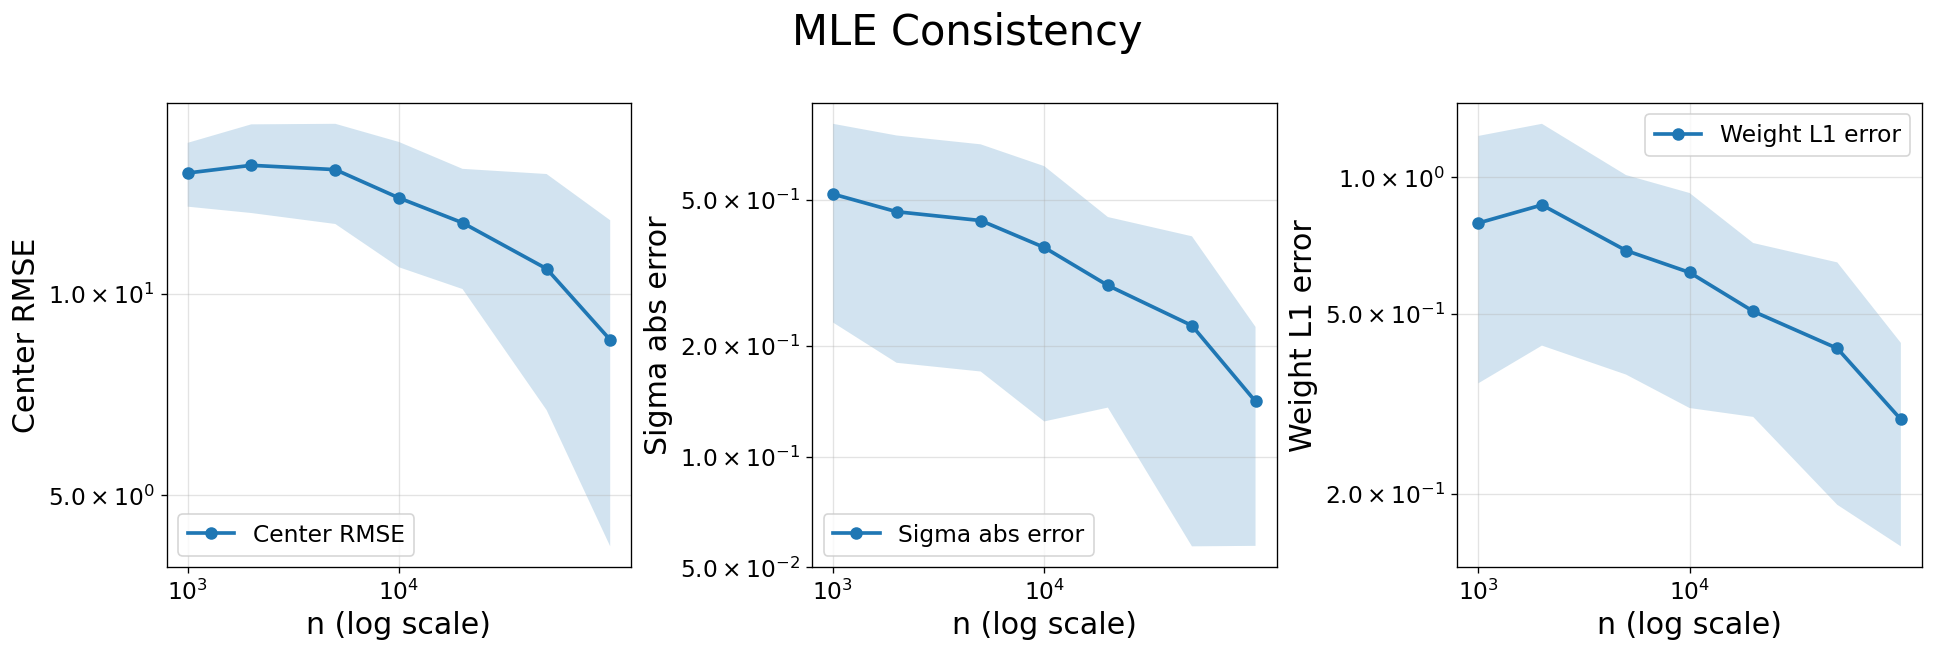

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# ---------------------------
# Your summary statistics
# ---------------------------
n = np.array([1000, 2000, 5000, 10000, 20000, 50000, 100000], dtype=float)

center_mean = np.array([15.1267, 15.5317, 15.3040, 13.8865,  12.7494,  10.8879, 8.5283])
center_std  = np.array([ 1.8839 ,  2.6772 ,  2.9743 ,  3.3562 ,  2.9604 ,  4.7763 , 4.9420 ])

wL1_mean = np.array([0.7930 , 0.8694, 0.6895, 0.6166, 0.5060, 0.4191, 0.2920])
wL1_std  = np.array([0.5044 , 0.5069  , 0.3681 , 0.3505 , 0.2399 , 0.2624 , 0.1585 ])

sigma_mean = np.array([0.5175, 0.4634, 0.4385, 0.3705, 0.2921, 0.2272, 0.1413])
sigma_std  = np.array([0.3261, 0.3233, 0.3058, 0.2804, 0.1781, 0.1941, 0.0959])

num_reps = 5  # used to convert std -> 95% CI

# ---------------------------
# Styling (paper-like)
# ---------------------------
plt.rcParams.update({
    "font.size": 16,
    "axes.titlesize": 18,
    "axes.labelsize": 18,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.35,
})

def ci95(std, reps):
    sem = std / np.sqrt(reps)
    return 1.96 * sem

def theoretical_rate(mean, n, scale=1.0):
    """
    Scaled 1/sqrt(n) reference line.
    By default anchored to mean[2], but you can bump it up with 'scale'.
    """
    return scale * mean[2] * np.sqrt(n[2] / n)


def sci_formatter(val, pos):
    """Format ticks as a×10^{b} (for log y-axis)."""
    if val <= 0:
        return ""
    exp = int(np.floor(np.log10(val)))
    coeff = val / (10**exp)
    return rf"${coeff:.1f}\times 10^{{{exp}}}$"

# ---------------------------
# Build the 1×3 panel (log–log)
# ---------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), constrained_layout=True)

panels = [
    ("Center RMSE", center_mean, center_std),
    ("Sigma abs error", sigma_mean, sigma_std),
    ("Weight L1 error", wL1_mean, wL1_std),
]

for ax, (ylabel, mean, std) in zip(axes, panels):
    # Axes: log–log so the 1/sqrt(n) reference is a straight line
    ax.set_xscale('log')
    ax.set_yscale('log')

    # x-axis ticks as 10^3, 10^4
    ax.set_xticks([1e3, 1e4])
    ax.get_xaxis().set_major_formatter(mtick.LogFormatterMathtext())
    ax.xaxis.set_minor_locator(mtick.NullLocator())

    # y-axis in "a×10^b" style
    ax.yaxis.set_major_locator(mtick.LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
    ax.yaxis.set_minor_locator(mtick.NullLocator())
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(sci_formatter))

    # 95% CI
    ci = ci95(std, num_reps)
    lower = np.clip(mean - ci, 1e-12, None)
    upper = np.clip(mean + ci, 1e-12, None)

    # empirical curve + CI band
    ax.plot(n, mean, '-o', linewidth=2.2, markersize=6.5, label=ylabel)
    ax.fill_between(n, lower, upper, alpha=0.20, linewidth=0)

    # # theoretical line (scaled only for center RMSE)
    # if "Center" in ylabel:
    #     ref = theoretical_rate(mean, n, scale=1.0)   # 🔼 bump this factor
    # elif "Sigma" in ylabel:
    #     ref = theoretical_rate(mean, n, scale=1.0)   # 🔼 bump this factor
    # else:
    #     ref = theoretical_rate(mean, n, scale=1.0)
    # ax.plot(n, ref, '--', linewidth=2.0, label='theoretical rate')

    # labels & legend
    ax.set_xlabel('n (log scale)')
    ax.set_ylabel(ylabel)
    ax.legend(loc='best')
    ax.set_box_aspect(1)



fig.suptitle("MLE Consistency", y=1.02, fontsize=25)

# Save & download in Colab
out_path = "/content/consistency_panels_loglog.png"
fig.savefig(out_path, dpi=900, bbox_inches="tight")
plt.show()

try:
    from google.colab import files
    files.download(out_path)
except Exception:
    print(f"Saved to {out_path}")


**Estimate m**

Generated dataset: n=20000, MH acceptance≈0.502
[scoring proposal] Defensive mixture: M=20000

[m-grid] Fitting m=1.3000 ...
Iteration 1/50  NLL=101661.872724  Δ=—
Iteration 2/50  NLL=101642.371093  Δ=1.95e+01
Iteration 3/50  NLL=101641.146361  Δ=1.22e+00
Iteration 4/50  NLL=101642.346026  Δ=1.20e+00
Iteration 5/50  NLL=101642.624518  Δ=2.78e-01
Iteration 6/50  NLL=101641.926344  Δ=6.98e-01
Iteration 7/50  NLL=101640.775534  Δ=1.15e+00
Iteration 8/50  NLL=101639.545194  Δ=1.23e+00
Iteration 9/50  NLL=101638.409030  Δ=1.14e+00
Iteration 10/50  NLL=101637.422394  Δ=9.87e-01
Iteration 11/50  NLL=101636.581172  Δ=8.41e-01
Iteration 12/50  NLL=101635.844860  Δ=7.36e-01
Iteration 13/50  NLL=101634.960721  Δ=8.84e-01
Iteration 14/50  NLL=101633.508707  Δ=1.45e+00
Iteration 15/50  NLL=101631.398164  Δ=2.11e+00
Iteration 16/50  NLL=101628.921707  Δ=2.48e+00
Iteration 17/50  NLL=101626.126914  Δ=2.79e+00
Iteration 18/50  NLL=101623.643850  Δ=2.48e+00
Iteration 19/50  NLL=101622.103352  Δ=1.54e+0

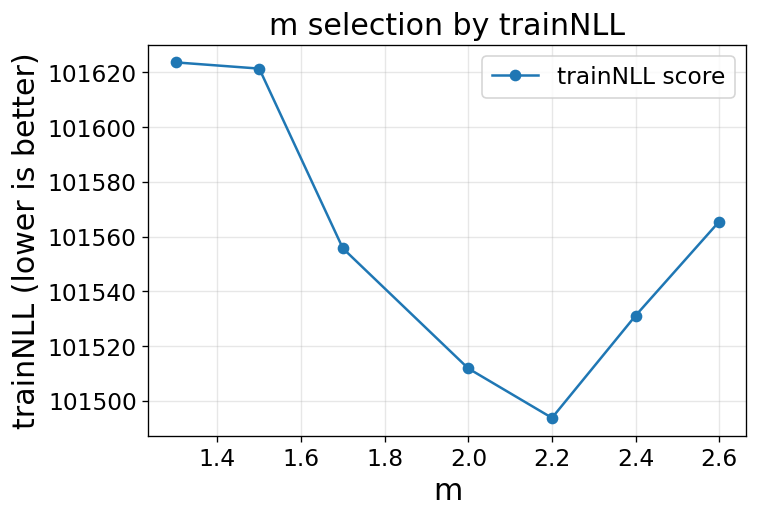

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.linalg import slogdet, inv

# ------------------------------------------------------------------
# NOTE: This file expects these functions to already exist (unchanged):
#   _normalize_w, target_density_ccluster,
#   em_like_fuzzy_clustering_c, generate_proposal_samples_gmm_c,
#   partial_negative_log_likelihood_full,
#   metropolis_hastings_ccluster (for the demo main)
# Do not modify them here — we only change m-selection utilities.
# ------------------------------------------------------------------

# ============================================================
# Utilities
# ============================================================

def _pack_full_params_from_fit(fit):
    """
    fit: dict returned by em_like_fuzzy_clustering_c
    -> 1D param vector compatible with partial_negative_log_likelihood_full
       [sigma, centers_flat, w]
    """
    sigma = float(fit["sigma"])
    centers = np.asarray(fit["centers"], float).ravel()
    w = _normalize_w(fit["w"])
    return np.r_[sigma, centers, w]


def _unpack_params_vec(params_vec, c, d):
    """Return (sigma, centers[c,d], w[c]) from flattened params."""
    sigma = float(params_vec[0])
    centers = np.asarray(params_vec[1:1 + c*d], dtype=float).reshape(c, d)
    w = _normalize_w(np.asarray(params_vec[1 + c*d:1 + c*d + c], dtype=float))
    return sigma, centers, w


def _num_params(c, d):
    """
    Parameter count for information criteria:
    sigma: 1
    centers: c * d
    weights on simplex: (c - 1)
    """
    return 1 + c * d + (c - 1)


def _ess_over_M(weights):
    """Effective sample size per draw for importance weights (can be normalized or not)."""
    w = np.asarray(weights, float).ravel()
    if w.size == 0:
        return np.nan
    denom = np.sum(w**2)
    if denom <= 0:
        return 0.0
    ess = (np.sum(w)**2) / denom
    return float(ess / max(len(w), 1))

# ---------- new stable helpers (selection-only) ----------

def _logmeanexp(a):
    """Stable log(mean(exp(a)))."""
    a = np.asarray(a, float).ravel()
    m = np.max(a)
    return float(m + np.log(np.mean(np.exp(a - m))))


def _ess_normalized_logw(logw):
    """
    ESS/M for self-normalized weights proportional to exp(logw).
    Returns ESS divided by M (in [0,1]).
    """
    lw = np.asarray(logw, float)
    lw -= np.max(lw)
    w = np.exp(lw)
    sw = np.sum(w)
    if sw <= 0 or not np.isfinite(sw):
        return 0.0
    w /= sw
    ess = 1.0 / np.sum(w**2)
    M = w.size if w.size else 1.0
    return float(ess / M)


def _make_defensive_scoring_proposal(
    X, *, M=20000, n_components=5, eps_mix=0.15, inflate=4.0, random_state=777
):
    """
    Build a defensive mixture proposal q_mix = (1-eps)*GMM + eps*N(mu, k*Cov),
    return (samples, log q_mix(samples)) for *scoring only*.
    Leaves your training proposal untouched.
    """
    rng = np.random.RandomState(random_state)

    # Fit GMM on data
    from sklearn.mixture import GaussianMixture
    gmm = GaussianMixture(n_components=n_components, covariance_type='full',
                          random_state=random_state)
    gmm.fit(X)

    # Defensive Gaussian N(mu, inflate*Cov)
    mu = X.mean(0)
    S = np.cov(X.T)
    d = X.shape[1]
    S_def = inflate * S + 1e-6 * np.eye(d)

    # Draw from mixture
    M_gmm = int((1.0 - eps_mix) * M)
    M_def = M - M_gmm
    Xgmm, _ = gmm.sample(M_gmm)
    Xdef = rng.multivariate_normal(mean=mu, cov=S_def, size=M_def)
    Xmix = np.vstack([Xgmm, Xdef])

    # log q_gmm
    logq_gmm = gmm.score_samples(Xmix)

    # log q_def (stable Mahalanobis)
    sign, logdetS = slogdet(S_def)
    const = -0.5 * (d * np.log(2*np.pi) + logdetS)
    Xm = Xmix - mu
    Sinv = inv(S_def)
    quad = np.einsum('ni,ij,nj->n', Xm, Sinv, Xm)
    logq_def = const - 0.5 * quad

    # log q_mix = log( (1-eps) e^{logq_gmm} + eps e^{logq_def} )
    a0 = np.log(1.0 - eps_mix) + logq_gmm
    a1 = np.log(eps_mix) + logq_def
    m = np.maximum(a0, a1)
    logq_mix = m + np.log(np.exp(a0 - m) + np.exp(a1 - m))

    return Xmix, logq_mix


def _stable_normalizer_estimate(params_vec, m, c, *, d, proposal_samples, logq_samples):
    """
    Stable log-IS estimate of Z with ESS/M diagnostic.
    Returns (Z_hat, C_hat, ESS_over_M, logZ).
    """
    sigma, centers, w = _unpack_params_vec(params_vec, c, d)
    Xp = np.asarray(proposal_samples, float)
    logq = np.asarray(logq_samples, float)

    # Evaluate *unnormalized* target at proposal points
    f_vals = target_density_ccluster(Xp, sigma=sigma, centers=centers, m=m, w=w)
    f_vals = np.clip(f_vals, 1e-300, np.inf)
    logf = np.log(f_vals)

    # importance log-weights: log(f/q)
    logw = logf - logq

    logZ = _logmeanexp(logw)
    Z_hat = float(np.exp(logZ))
    C_hat = 1.0 / max(Z_hat, 1e-300)
    essM = _ess_normalized_logw(logw)
    return Z_hat, C_hat, essM, logZ


def _estimate_normalizer_via_is(params_vec, m, c, *, d, proposal_samples, proposal_weights):
    """Simple IS normalizer using linear weights w = f/q."""
    sigma, centers, w = _unpack_params_vec(params_vec, c, d)
    f = target_density_ccluster(proposal_samples, sigma=sigma, centers=centers, m=m, w=w)
    ratio = f / (proposal_weights + 1e-300)
    Z_hat = float(np.mean(ratio))
    C_hat = 1.0 / max(Z_hat, 1e-300)
    return Z_hat, C_hat


# ============================================================
# Likelihood & Normalizer evaluation helpers (unchanged API)
# ============================================================

def _compute_full_nll(params_vec, data, m, c,
                      proposal_samples=None, proposal_weights=None,
                      n_comp_gmm=3, random_state=1234):
    """
    Compute IS-normalized NLL on 'data' for given parameter vector.
    If proposal samples are not provided, fit a small GMM to 'data' to make them.
    """
    if proposal_samples is None or proposal_weights is None:
        proposal_samples, proposal_weights, _ = generate_proposal_samples_gmm_c(
            data, num_samples=min(5000, max(2000, 5 * c * data.shape[1])),
            n_components=n_comp_gmm, random_state=random_state
        )
    return partial_negative_log_likelihood_full(
        params_vec, data, proposal_samples, proposal_weights, m, c
    )


# ============================================================
# Post-EM joint optimization of the FULL NLL (added)
# ============================================================

def optimize_full_nll_from(
    params_start, *, data, proposal_samples, proposal_weights, m, c, d,
    sigma_bounds=(1e-5, 100.0), w_bounds_low=1e-6, max_iter=200, tol=1e-6, verbose=False
):
    """
    Jointly optimize FULL NLL over [sigma, centers, w] with L-BFGS-B
    starting from params_start = [sigma, centers_flat, w].
    Returns: params_opt, nll_opt, opt_iters, success, message
    """
    from scipy.optimize import minimize

    n_cent = c * d
    # bounds: sigma, centers (unbounded), w in [w_bounds_low, 1]
    bounds = [sigma_bounds] + [(None, None)] * n_cent + [(w_bounds_low, 1.0)] * c

    itercount = {"k": 0}
    def _cb(xk):
        itercount["k"] += 1

    def _obj(theta):
        return partial_negative_log_likelihood_full(
            theta, data, proposal_samples, proposal_weights, m, c
        )

    res = minimize(
        _obj, np.array(params_start, float),
        method="L-BFGS-B", bounds=bounds,
        options={"maxiter": int(max_iter), "ftol": float(tol)},
        callback=_cb
    )

    params_opt = np.array(res.x, float)
    nll_opt = float(res.fun)
    opt_iters = int(itercount["k"])
    if verbose:
        status = "OK" if res.success else "FAIL"
        print(f"  [full NLL opt] status={status} iters={opt_iters} nll={nll_opt:.6f}")
    return params_opt, nll_opt, opt_iters, bool(res.success), str(res.message)


# ============================================================
# One-m fit routine (estimation + post-EM full-NLL refine)
# ============================================================

def _fit_for_m(
    data, c, m, *,
    is_samples=5000, n_components_gmm=3, fit_max_iter=40,
    init_centers=None, init_sigma=1.0, init_w=None,
    centroid_damping=0.9, random_state=1234, verbose=False,
    # new optimizer controls
    gd_max_iter=200, gd_tol=1e-6
):
    """
    Fit the EM-like estimator for a given m on 'data', then
    run a JOINT L-BFGS-B on the FULL NLL starting from EM params.

    Returns:
      fit_dict, params_vec_opt, proposal_samples, proposal_weights, train_nll_opt
    """
    # Proposal draws for training NLL
    proposal_samples, proposal_weights, _ = generate_proposal_samples_gmm_c(
        data, num_samples=is_samples, n_components=n_components_gmm, random_state=random_state + 99
    )

    # ----- EM-like fit (unchanged)
    fit = em_like_fuzzy_clustering_c(
        data=data,
        proposal_samples=proposal_samples,
        proposal_weights=proposal_weights,
        m=m, c=c,
        initial_sigma=init_sigma,
        initial_centers=init_centers,
        initial_w=init_w,
        max_iter=fit_max_iter,
        random_state=random_state + 123,
        centroid_damping=centroid_damping
    )
    params_vec_em = _pack_full_params_from_fit(fit)

    # ----- NEW: full-NLL refine from EM params
    d = data.shape[1]
    params_vec_opt, nll_opt, opt_iters, ok, msg = optimize_full_nll_from(
        params_vec_em,
        data=data,
        proposal_samples=proposal_samples,
        proposal_weights=proposal_weights,
        m=m, c=c, d=d,
        max_iter=gd_max_iter,
        tol=gd_tol,
        verbose=verbose
    )

    # training NLL with optimized params
    train_nll_opt = partial_negative_log_likelihood_full(
        params_vec_opt, data, proposal_samples, proposal_weights, m, c
    )

    if verbose:
        # compute ESS/M on training proposal using *importance* weights ratio = f/q
        sigma_, centers_, w_ = _unpack_params_vec(params_vec_opt, c, d)
        f_vals = target_density_ccluster(proposal_samples, sigma_, centers_, m, w_)
        ratio = f_vals / (proposal_weights + 1e-300)
        ess_over_M = (np.sum(ratio)**2) / (len(ratio) * np.sum(ratio**2) + 1e-300)
        print(f"  [train proposal] M={len(proposal_weights)}, ESS/M≈{ess_over_M:.3f}")
        print(f"  [post-EM full NLL] iters_used={opt_iters}")

    # carry optimizer info in fit (non-breaking; just extra fields)
    fit["opt_iters_full_nll"] = int(opt_iters)
    fit["opt_success_full_nll"] = bool(ok)

    return fit, params_vec_opt, proposal_samples, proposal_weights, float(train_nll_opt)


# ============================================================
# m-grid selection with robust (stable) scoring
# ============================================================

def select_m_grid(
    data, c, d, m_grid,
    *,
    criterion="BIC",                 # "BIC", "AIC", "trainNLL", "valNLL"
    val_frac=0.25,                   # used if criterion=="valNLL"
    is_samples=5000,
    n_components_gmm=3,
    fit_max_iter=40,
    init_near_truth=False,           # set True if you want to warm start near known truth
    truth_centers=None,
    truth_sigma=1.0,
    truth_w=None,
    init_jitter=0.2,
    centroid_damping=0.9,
    random_state=2025,
    reuse_shared_scoring_proposal=True,    # use shared defensive proposal for scoring & Z_hat
    eps_mix=0.15,                            # defensive mixture weight
    inflate=4.0,                             # covariance inflation for defensive Gaussian
    ess_soft_thresholds=(0.10, 0.05),        # (mild, severe) ESS/M thresholds for penalty
    ess_penalty_strength=(0.005, 0.02),      # penalty multipliers per N (mild, severe)
    verbose=True,
    # new optimizer controls (forwarded to _fit_for_m)
    gd_max_iter=200, gd_tol=1e-6
):
    """
    Grid-search over m for a fixed dataset.
    Returns: dict with per-m scores, best m, and the fitted model for the best m,
             plus Z_hat, C_hat, ESS/M for each m.

    Estimation is unchanged; only scoring uses a stable defensive proposal.
    """
    rng = np.random.RandomState(random_state)
    N = data.shape[0]
    k = _num_params(c, d)

    # Optional split for validation criterion
    if criterion == "valNLL":
        idx = rng.permutation(N)
        n_val = int(np.floor(val_frac * N))
        val_idx, tr_idx = idx[:n_val], idx[n_val:]
        Xtr, Xval = data[tr_idx], data[val_idx]
        if verbose:
            print(f"[m-grid] Using validation split: train={Xtr.shape[0]}, val={Xval.shape[0]}")
    else:
        Xtr = data
        Xval = None

    # Prepare init for EM
    if init_near_truth and (truth_centers is not None) and (truth_w is not None):
        init_centers0 = np.asarray(truth_centers, float) + init_jitter * rng.randn(c, d)
        init_sigma0 = max(1e-2, float(truth_sigma) + 0.05 * rng.randn())
        init_w0 = _normalize_w(np.asarray(truth_w, float) + 0.01 * rng.randn(c))
    else:
        init_centers0 = None
        init_sigma0 = 1.0
        init_w0 = None

    # Shared defensive proposal for scoring & normalizer estimation
    if reuse_shared_scoring_proposal:
        shared_X, shared_logq = _make_defensive_scoring_proposal(
            Xtr, M=is_samples, n_components=n_components_gmm,
            eps_mix=eps_mix, inflate=inflate, random_state=random_state + 777
        )
        if verbose:
            print(f"[scoring proposal] Defensive mixture: M={shared_X.shape[0]}")
    else:
        shared_X = shared_logq = None

    records = []   # collect per-m results
    best = None    # track best by criterion

    mild_thr, severe_thr = ess_soft_thresholds
    mild_k, severe_k = ess_penalty_strength

    for m0 in m_grid:
        if verbose:
            print(f"\n[m-grid] Fitting m={m0:.4f} ...")

        fit_m, params_vec, tr_prop_samples, tr_prop_weights, train_nll = _fit_for_m(
            Xtr, c, m0,
            is_samples=is_samples, n_components_gmm=n_components_gmm, fit_max_iter=fit_max_iter,
            init_centers=init_centers0, init_sigma=init_sigma0, init_w=init_w0,
            centroid_damping=centroid_damping, random_state=random_state + int(1000 * (m0 * 7.123)),
            verbose=verbose, gd_max_iter=gd_max_iter, gd_tol=gd_tol
        )

        # ----- robust scoring with shared defensive proposal -----
        if reuse_shared_scoring_proposal:
            # energy term for current params on Xtr (aligned with note)
            sigma_, centers_, w_ = _unpack_params_vec(params_vec, c, d)
            diffs = Xtr[:, None, :] - centers_[None, :, :]
            dnorm = np.linalg.norm(diffs, axis=2) + 1e-8
            dist_power = w_[None, :] * (dnorm ** (-2.0 / (m0 - 1.0)))
            denom_data_tr = (np.sum(dist_power, axis=1) + 1e-8) ** (m0 - 1.0)
            energy_tr = np.sum(1.0 / (sigma_**2 * denom_data_tr + 1e-8))

            Z_hat, C_hat, essM, logZ = _stable_normalizer_estimate(
                params_vec, m0, c, d=d, proposal_samples=shared_X, logq_samples=shared_logq
            )
            nll_scoring_train = Xtr.shape[0] * logZ + energy_tr
            base_nll_for_score = nll_scoring_train

            if criterion == "valNLL":
                # recompute energy on validation, reuse logZ (data-independent)
                diffs_val = Xval[:, None, :] - centers_[None, :, :]
                dnorm_val = np.linalg.norm(diffs_val, axis=2) + 1e-8
                dist_power_val = w_[None, :] * (dnorm_val ** (-2.0 / (m0 - 1.0)))
                denom_data_val = (np.sum(dist_power_val, axis=1) + 1e-8) ** (m0 - 1.0)
                energy_val = np.sum(1.0 / (sigma_**2 * denom_data_val + 1e-8))
                base_nll_for_score = Xval.shape[0] * logZ + energy_val
        else:
            # fall back to per-m training proposal
            base_nll_for_score = float(train_nll)
            # quick Z estimate for reporting (not used for scoring)
            Z_hat, C_hat = _estimate_normalizer_via_is(
                params_vec, m0, c, d=d, proposal_samples=tr_prop_samples, proposal_weights=tr_prop_weights
            )
            essM = _ess_over_M(tr_prop_weights)

        # ----- ESS-based soft penalty -----
        penalty = 0.0
        if reuse_shared_scoring_proposal:
            if essM < severe_thr and severe_thr > 0:
                penalty = (severe_thr / max(essM, 1e-6) - 1.0) * (severe_k * N)
            elif essM < mild_thr and mild_thr > 0:
                penalty = (mild_thr / max(essM, 1e-6) - 1.0) * (mild_k * N)

        # ----- criteria -----
        if criterion == "trainNLL":
            score = float(base_nll_for_score + penalty)
        elif criterion == "AIC":
            score = np.log(np.e) * 2 * k + 2 * float(base_nll_for_score + penalty)  # same as 2k + 2NLL
        elif criterion == "BIC":
            score = np.log(N) * k + 2 * float(base_nll_for_score + penalty)
        elif criterion == "valNLL":
            score = float(base_nll_for_score + penalty)
        else:
            raise ValueError("criterion must be one of: 'trainNLL', 'AIC', 'BIC', 'valNLL'.")

        rec = {
            "m": float(m0),
            "train_nll": float(train_nll),
            "score": float(score),
            "criterion": criterion,
            "fit": fit_m,
            "params_vec": params_vec,          # already post-EM optimized
            "Z_hat": float(Z_hat),
            "C_hat": float(C_hat),
            "ess_over_M": float(essM),
            "opt_iters": int(fit_m.get("opt_iters_full_nll", 0)),  # expose optimizer iters
        }
        records.append(rec)

        if verbose:
            print(f"  -> train NLL (per-m proposal, post-EM opt) = {float(train_nll):.3f}")
            print(f"  -> {criterion} score (defensive scoring) = {float(score):.3f}  | ESS/M≈{essM:.3f}")
            print(f"  -> normalizer (defensive): Z_hat ≈ {Z_hat:.6e}  =>  C_hat ≈ {C_hat:.6e}")
            print(f"  -> full NLL optimizer iters used = {rec['opt_iters']}")

        if (best is None) or (score < best["score"]):
            best = rec

    # Summary table: [m, train_nll, score, Z_hat, C_hat, ess/M] ordered by score asc.
    table = np.array(
        [(r["m"], r["train_nll"], r["score"], r["Z_hat"], r["C_hat"], r["ess_over_M"]) for r in records],
        dtype=float
    )
    order = np.argsort(table[:, 2])  # by score ascending
    table = table[order]

    result = {
        "criterion": criterion,
        "records": records,
        "summary_table": table,  # columns: [m, train_nll, score, Z_hat, C_hat, ess/M]
        "best": best
    }
    return result


# ============================================================
# Plot helper: connect points in the order of m
# ============================================================

def plot_m_selection(result, title="m selection", outpath=None):
    """
    Connect the curve in increasing m (x-axis).
    """
    tab = result["summary_table"]
    # summary_table is already sorted by score; we want to sort by m for plotting connectivity
    ms = tab[:, 0]
    scores = tab[:, 2]

    # Order by m (not by score)
    idx = np.argsort(ms)
    ms_plot = ms[idx]
    scores_plot = scores[idx]
    crit = result["criterion"]

    plt.figure(figsize=(6.6, 4.6))
    plt.plot(ms_plot, scores_plot, marker='o', linestyle='-',
             label=f"{crit} score")
    plt.xlabel("m")
    plt.ylabel(f"{crit} (lower is better)")
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    if outpath:
        plt.savefig(outpath, dpi=300, bbox_inches="tight")
        plt.close()
    else:
        plt.show()


# ============================================================
# Example main (uses your *unchanged* pieces)
# ============================================================
if __name__ == "__main__":
    # --- choose truth & generate one dataset via your MH sampler ---
    d = 3
    c_true = 3
    m_true_for_data = 2.0   # true m used to generate data
    centers_true = np.array([
        [ 0.0,  0.0, 0.0],
        [10.0,  0.0,-1.0],
        [-10.0,  2.5, 1.0],
    ], dtype=float)
    w_true = np.array([0.70, 0.10, 0.20], dtype=float)
    w_true = _normalize_w(w_true)
    sigma_true = 2.0

    # Use your provided MH sampler
    try:
        data_pool, acc = metropolis_hastings_ccluster(
            target_density=target_density_ccluster,
            initial_point=np.zeros(d),
            sigma=sigma_true, centers=centers_true, m=m_true_for_data, w=w_true,
            iterations=30000, proposal_std=1.0, burn_in=0.20, seed=123
        )
    except NameError:
        raise RuntimeError(
            "Please ensure metropolis_hastings_ccluster(...) is available. "
            "Leave your sampler unchanged; this file only revises m-selection."
        )

    n_fixed = 20000
    X = data_pool[:n_fixed]
    print(f"Generated dataset: n={X.shape[0]}, MH acceptance≈{acc:.3f}")

    # --- grid of m values to test ---
    m_grid = [1.3, 1.5, 1.7, 2.0, 2.2, 2.4, 2.6]

    # --- run selection (robust scoring; estimation unchanged) ---
    sel = select_m_grid(
        data=X, c=c_true, d=d, m_grid=m_grid,
        criterion="trainNLL",              # "BIC", "AIC", "trainNLL", or "valNLL"
        val_frac=0.25,                     # used only if criterion="valNLL"
        is_samples=20000,                  # IS samples for scoring & Z_hat (shared)
        n_components_gmm=5,
        fit_max_iter=50,
        init_near_truth=True,              # warm start (optional)
        truth_centers=centers_true,
        truth_sigma=sigma_true,
        truth_w=w_true,
        init_jitter=0.2,
        centroid_damping=0.9,
        random_state=2026,
        reuse_shared_scoring_proposal=True,   # use defensive mixture for fairness
        eps_mix=0.15,
        inflate=4.0,
        ess_soft_thresholds=(0.10, 0.05),
        ess_penalty_strength=(0.005, 0.02),
        verbose=True,
        # new: post-EM full NLL optimizer defaults
        gd_max_iter=200, gd_tol=1e-6
    )

    # --- print summary
    print("\n=== m-selection summary (sorted by score) ===")
    print("   m       trainNLL         score             C_hat        ESS/M   optIters")
    for rec in sorted(sel["records"], key=lambda r: r["score"]):
        print(f"{rec['m']:5.1f}   {rec['train_nll']:12.3f}   {rec['score']:12.3f}    "
              f"{rec['C_hat']:12.6e}   {rec['ess_over_M']:7.3f}   {rec.get('opt_iters',0):8d}")

    best = sel["best"]
    print(f"\nBest m by {sel['criterion']}: m* = {best['m']:.3f}")
    print(f"Estimated normalizer for best m*:  C_hat ≈ {best['C_hat']:.6e}  (Z_hat ≈ {best['Z_hat']:.6e})")

    # Optional: quick plot (connected by increasing m)
    plot_m_selection(sel, title=f"m selection by {sel['criterion']}")


流式输出内容被截断，只能显示最后 5000 行内容。
Iteration 20/50  NLL=101588.407347  Δ=2.82e+00
Iteration 21/50  NLL=101584.845816  Δ=3.56e+00
Iteration 22/50  NLL=101580.742273  Δ=4.10e+00
Iteration 23/50  NLL=101576.550720  Δ=4.19e+00
Iteration 24/50  NLL=101572.810705  Δ=3.74e+00
Iteration 25/50  NLL=101576.990250  Δ=4.18e+00
Iteration 26/50  NLL=101590.764565  Δ=1.38e+01
Iteration 27/50  NLL=101593.868979  Δ=3.10e+00
Iteration 28/50  NLL=101594.505157  Δ=6.36e-01
Iteration 29/50  NLL=101594.586610  Δ=8.15e-02
Iteration 30/50  NLL=101594.593829  Δ=7.22e-03
Iteration 31/50  NLL=101594.594300  Δ=4.70e-04
Iteration 32/50  NLL=101594.593911  Δ=3.88e-04
Iteration 33/50  NLL=101594.594091  Δ=1.80e-04
Iteration 34/50  NLL=101594.593836  Δ=2.56e-04
Iteration 35/50  NLL=101594.594080  Δ=2.44e-04
Iteration 36/50  NLL=101594.593832  Δ=2.48e-04
Iteration 37/50  NLL=101594.594080  Δ=2.48e-04
Iteration 38/50  NLL=101594.593831  Δ=2.49e-04
Iteration 39/50  NLL=101594.594077  Δ=2.46e-04
Iteration 40/50  NLL=101594.59382

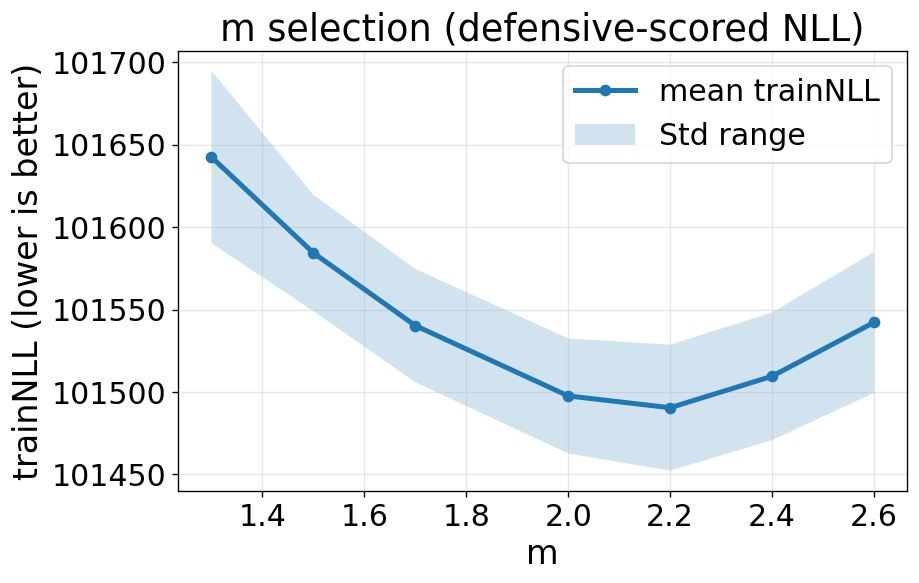

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# Repeated runs (different seeds) + aggregation  — ALIGNED VERSION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

def run_m_grid_repeats(
    data, c, d, m_grid, repeats=1, *,          # default 1 to match the single-run first script
    base_seed=2026,                             # match first script's random_state
    # everything below is passed through to select_m_grid
    criterion="trainNLL",
    is_samples=20000,
    n_components_gmm=5,
    fit_max_iter=50,
    init_near_truth=False,
    truth_centers=None,
    truth_sigma=1.0,
    truth_w=None,
    init_jitter=0.2,
    centroid_damping=0.9,
    reuse_shared_scoring_proposal=True,
    eps_mix=0.15,
    inflate=4.0,
    ess_soft_thresholds=(0.10, 0.05),
    ess_penalty_strength=(0.005, 0.02),
    verbose=False
):
    """
    Repeat select_m_grid 'repeats' times with different seeds.
    Aggregates the SAME score the first script plots: 'rec["score"]'
      (defensive-scored NLL + ESS penalty, when reuse_shared_scoring_proposal=True).
    Returns:
      runs: list of 'sel' dicts from select_m_grid (length = repeats)
      agg:  dict with per-m arrays and summary stats for SCORE plus diagnostics
    """
    runs = []
    # aggregate containers
    per_m_score   = {float(m): [] for m in m_grid}
    per_m_ESSM    = {float(m): [] for m in m_grid}
    per_m_Chat    = {float(m): [] for m in m_grid}
    per_m_trainNL = {float(m): [] for m in m_grid}  # optional: keep trainNLL for reference

    for r in range(repeats):
        seed_r = int(base_seed + 1000*r)
        sel = select_m_grid(
            data=data, c=c, d=d, m_grid=m_grid,
            criterion=criterion,
            val_frac=0.25,
            is_samples=is_samples,
            n_components_gmm=n_components_gmm,
            fit_max_iter=fit_max_iter,
            init_near_truth=init_near_truth,
            truth_centers=truth_centers,
            truth_sigma=truth_sigma,
            truth_w=truth_w,
            init_jitter=init_jitter,
            centroid_damping=centroid_damping,
            random_state=seed_r,
            reuse_shared_scoring_proposal=reuse_shared_scoring_proposal,
            eps_mix=eps_mix,
            inflate=inflate,
            ess_soft_thresholds=ess_soft_thresholds,
            ess_penalty_strength=ess_penalty_strength,
            verbose=verbose
        )
        runs.append(sel)

        # Pull score (defensive) + diagnostics per m
        for rec in sel["records"]:
            m0 = float(rec["m"])
            per_m_score[m0].append(float(rec["score"]))
            per_m_ESSM[m0].append(float(rec["ess_over_M"]))
            per_m_Chat[m0].append(float(rec["C_hat"]))
            per_m_trainNL[m0].append(float(rec["train_nll"]))  # optional

    # summarize
    ms = np.array(sorted(per_m_score.keys()))
    score_mean = np.array([np.mean(per_m_score[m]) for m in ms])
    score_std  = np.array([np.std (per_m_score[m], ddof=1) if len(per_m_score[m])>1 else 0.0 for m in ms])

    ess_mean = np.array([np.mean(per_m_ESSM[m]) for m in ms])
    ess_std  = np.array([np.std (per_m_ESSM[m], ddof=1) if len(per_m_ESSM[m])>1 else 0.0 for m in ms])

    Chat_mean = np.array([np.mean(per_m_Chat[m]) for m in ms])
    Chat_std  = np.array([np.std (per_m_Chat[m], ddof=1) if len(per_m_Chat[m])>1 else 0.0 for m in ms])

    trainNLL_mean = np.array([np.mean(per_m_trainNL[m]) for m in ms])
    trainNLL_std  = np.array([np.std (per_m_trainNL[m], ddof=1) if len(per_m_trainNL[m])>1 else 0.0 for m in ms])

    agg = {
        "m": ms,
        "score_mean": score_mean,
        "score_std":  score_std,
        "ess_mean": ess_mean,
        "ess_std":  ess_std,
        "C_hat_mean": Chat_mean,
        "C_hat_std":  Chat_std,
        "trainNLL_mean": trainNLL_mean,   # for reference
        "trainNLL_std":  trainNLL_std,    # for reference
        "repeats": repeats,
        "criterion": criterion,
    }
    return runs, agg


# ============================================================
# Plot: criterion score vs m with error band (matches first script’s score)
# ============================================================

def plot_m_selection_score(agg, title=None, out_png="m_score_mean.png", out_pdf=None):
    """
    Draw mean 'score' (defensive-scored NLL + ESS penalty) vs m with ±1 std shaded band.
    """
    m    = np.asarray(agg["m"])
    mu   = np.asarray(agg["score_mean"])
    sd   = np.asarray(agg["score_std"])
    crit = agg.get("criterion", "score")

    # big fonts
    plt.rcParams.update({
        "font.size": 18,
        "axes.titlesize": 22,
        "axes.labelsize": 20,
        "xtick.labelsize": 18,
        "ytick.labelsize": 18,
        "legend.fontsize": 18
    })

    # sort by m
    idx = np.argsort(m)
    m, mu, sd = m[idx], mu[idx], sd[idx]

    plt.figure(figsize=(8.0, 5.2))
    plt.plot(m, mu, marker='o', linewidth=3, label=f"mean {crit}")
    if np.any(sd > 0):
        plt.fill_between(m, mu - sd, mu + sd, alpha=0.2, label="Std range")

    plt.xlabel("m")
    plt.ylabel(f"{crit} (lower is better)")
    plt.title(title or f"m selection by {crit}")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    if out_png:
        plt.savefig(out_png, dpi=900, bbox_inches="tight")
    if out_pdf:
        plt.savefig(out_pdf, dpi=900, bbox_inches="tight")
    plt.show()


# ============================================================
# Example main (uses your *unchanged* pieces), aligned to first script
# ============================================================
if __name__ == "__main__":
    # --- choose truth & generate one dataset via your MH sampler ---
    d = 3
    c_true = 3
    m_true_for_data = 2.0   # true m used to generate data

    # ALIGNED centers with the first script:
    centers_true = np.array([
        [  0.0,  0.0, 0.0],
        [ 10.0,  0.0,-1.0],   # <- y=0.0 (not -2.5)
        [-10.0,  2.5, 1.0],
    ], dtype=float)

    w_true = _normalize_w(np.array([0.70, 0.10, 0.20], dtype=float))
    sigma_true = 2.0

    # Use your provided MH sampler (unchanged)
    data_pool, acc = metropolis_hastings_ccluster(
        target_density=target_density_ccluster,
        initial_point=np.zeros(d),
        sigma=sigma_true, centers=centers_true, m=m_true_for_data, w=w_true,
        iterations=30000, proposal_std=1.0, burn_in=0.20, seed=123
    )

    n_fixed = 20000
    X = data_pool[:n_fixed]
    print(f"Generated dataset: n={X.shape[0]}, MH acceptance≈{acc:.3f}")

    # --- grid of m values to test (same as first script) ---
    m_grid = [1.3, 1.5, 1.7, 2.0, 2.2, 2.4, 2.6]

    # === repeats kept at 1 to mirror the first script (set >1 for error bands) ===
    repeats = 30

    # --- run repeats (estimation unchanged; defensive scoring like first script) ---
    runs, agg = run_m_grid_repeats(
        data=X, c=c_true, d=d, m_grid=m_grid, repeats=repeats,
        base_seed=2026,                      # same random_state as first select_m_grid demo
        criterion="trainNLL",               # same criterion (uses defensive scoring internally)
        is_samples=20000,
        n_components_gmm=5,
        fit_max_iter=50,
        init_near_truth=True,               # match first’s warm start
        truth_centers=centers_true,
        truth_sigma=sigma_true,
        truth_w=w_true,
        init_jitter=0.2,
        centroid_damping=0.9,
        reuse_shared_scoring_proposal=True, # defensive mixture
        eps_mix=0.15,
        inflate=4.0,
        ess_soft_thresholds=(0.10, 0.05),
        ess_penalty_strength=(0.005, 0.02),
        verbose=False
    )

    # --- print aggregated table (now for SCORE to match what the first script plots) ---
    print("\n=== Aggregated over repeats (SCORE = defensive NLL + ESS penalty) ===")
    print("   m       mean(score)      std(score)      mean(ESS/M)       mean(C_hat)")
    for m0, mu, sd, ess, Chat in zip(
        agg["m"], agg["score_mean"], agg["score_std"], agg["ess_mean"], agg["C_hat_mean"]
    ):
        print(f"{m0:5.1f}   {mu:14.3f}   {sd:13.3f}   {ess:13.3f}   {Chat:13.6e}")

    # --- plot (mean ± 1 std) using SCORE (matches first script’s objective) ---
    plot_m_selection_score(
        agg,
        title="m selection (defensive-scored NLL)",
        out_png="m_score_mean.png",
        out_pdf="m_score_mean.pdf"
    )

    # Optional: also make the trainNLL plot for reference (not used in first script)
    # from the previous version:
    # plot_m_selection_trainNLL(agg, title="m selection (train NLL, ref)",
    #                           out_png="m_trainNLL_mean.png", out_pdf="m_trainNLL_mean.pdf")

    try:
        from google.colab import files
        files.download("m_score_mean.png")
        files.download("m_score_mean.pdf")
    except Exception:
        pass


**Asymptotic normality**

In [ ]:
# ===============================================
# FAST Asymptotic Normality Check (with plots)
# - Whitening via empirical covariance across replicates
# - Single MH chain per replicate (slice for all n)
# - Diagnostic plots to verify normality
# ===============================================
import numpy as np
from numpy.linalg import cholesky, solve, LinAlgError, eigh
from scipy.optimize import minimize
from scipy.stats import kstest, norm, chi2
from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt
import time
import os

# ---------------------------
# True model (2D, c=2, m=2)
# ---------------------------
c = 2
m = 2.0
centers_true = np.array([[0.0, 0.0],
                         [3.5, 3.5]])
w_true = np.array([0.8, 0.2])
sigma_true = 2.0

# ---------------------------
# FAST config
# ---------------------------
np.random.seed(123)

# sample sizes and replicates
n_list   = [500, 2000, 10000]      # add 10000 later if needed
B_per_n  = 100               # increase for nicer plots

# MH chain
MH_iters_max = 20000        # long chain ONCE per replicate, then slice
MH_burn      = 0.2
prop_std     = 1.2

# GMM proposal (used only inside the MLE objective's normalizer)
n_components_gmm = 3
M_IS = 5000                 # importance samples (fixed, small)

# plotting options
SAVE_PLOTS = False          # set True to save to disk
OUTDIR_BASE = "normality_plots"  # folder for saved plots

# ---------------------------
# Reparameterization utils
# ---------------------------
def softmax(logits):
    m = np.max(logits)
    e = np.exp(logits - m)
    return e / (np.sum(e) + 1e-12)

def weights_from_free(a, eps_floor=1e-3):
    a = np.asarray(a, float)
    logits = np.r_[a, 0.0]
    w_raw = softmax(logits)
    c_ = w_raw.size
    return eps_floor + (1.0 - c_*eps_floor) * w_raw

def free_from_weights(w, eps=1e-12):
    w = np.asarray(w, float); w = w / (w.sum() + eps)
    return np.log(np.maximum(w[:-1], eps) / max(w[-1], eps))

def pack_free_params(s_log, centers, a):
    return np.r_[s_log, centers.ravel(), a]

def unpack_free_params(p, c):
    s_log = p[0]
    sigma = np.exp(s_log)
    centers = p[1:1+2*c].reshape((c,2))
    a = p[1+2*c:]
    w = weights_from_free(a)
    return sigma, centers, w

# ---------------------------
# Density + NLL (vectorized)
# ---------------------------
def target_density_ccluster(x, sigma, centers, m, w, eps=1e-8):
    # x: (N,2), centers: (c,2)
    diffs = x[:, None, :] - centers[None, :, :]        # (N,c,2)
    d = np.linalg.norm(diffs, axis=2) + eps            # (N,c)
    dist_power = w[None, :] * d ** (-2.0 / (m - 1.0))  # (N,c)
    s = dist_power.sum(axis=1)                          # (N,)
    denom = (s) ** (m - 1.0)                        # (N,)
    exponent = -1.0 / (sigma**2 * denom + eps)
    return np.exp(exponent)

def NLL_freeparams(p, data, propsamp, prop_pdf, m, c, eps=1e-8):
    sigma, centers, w = unpack_free_params(p, c)
    # energy term
    diffs = data[:, None, :] - centers[None, :, :]
    d = np.linalg.norm(diffs, axis=2) + eps
    dist_power = w[None, :] * d ** (-2.0 / (m - 1.0))
    denom_data = (dist_power.sum(axis=1) + eps) ** (m - 1.0)
    energy = np.sum(1.0 / (sigma**2 * denom_data + eps))
    # IS normalizer (fixed CRNs)
    f_x = target_density_ccluster(propsamp, sigma, centers, m, w, eps)
    ratio = f_x / (prop_pdf + 1e-12)
    Z_est = np.mean(ratio) + 1e-12
    return data.shape[0] * np.log(Z_est) + energy

# ---------------------------
# MH sampler (once per replicate)
# ---------------------------
def mh_sample(initial_point, sigma, centers, m, w,
              iters=20000, prop_std=1.2, burn=0.2, seed=0):
    rng = np.random.RandomState(seed)
    samples = np.zeros((iters, 2))
    samples[0] = initial_point
    accepted = 0
    curr_val = target_density_ccluster(samples[0][None,:], sigma, centers, m, w)[0]
    for i in range(1, iters):
        prop = samples[i-1] + rng.randn(2)*prop_std
        prop_val = target_density_ccluster(prop[None,:], sigma, centers, m, w)[0]
        alpha = min(1.0, prop_val / (curr_val + 1e-12))
        if rng.rand() < alpha:
            samples[i] = prop
            curr_val = prop_val
            accepted += 1
        else:
            samples[i] = samples[i-1]
    b = int(iters * burn)
    return samples[b:], accepted / (iters - 1)

# ---------------------------
# GMM proposal (once per (replicate, n))
# ---------------------------
def make_proposal(X, n_components, M, random_state=7):
    gmm = GaussianMixture(n_components=n_components, covariance_type='full', random_state=random_state)
    gmm.fit(X)
    propsamp, _ = gmm.sample(M)
    prop_pdf = np.exp(gmm.score_samples(propsamp))
    return propsamp, prop_pdf, gmm

# ---------------------------
# MLE run (fixed CRNs)
# ---------------------------
def mle_run(data, m, c, propsamp, prop_pdf, init_sigma=1.0, random_state=0):
    rng = np.random.RandomState(random_state)
    N = data.shape[0]
    centers0 = data[rng.choice(N, c, replace=False)].copy()
    w0 = np.ones(c)/c
    s0 = np.log(init_sigma)
    a0 = free_from_weights(w0)
    p0 = pack_free_params(s0, centers0, a0)
    obj = lambda p: NLL_freeparams(p, data, propsamp, prop_pdf, m, c)
    res = minimize(obj, p0, method="L-BFGS-B")
    return res.x, unpack_free_params(res.x, c), res

# ---------------------------
# Label alignment (c=2)
# ---------------------------
def align_labels(theta_hat, theta_true):
    sigma_h, Vh, wh = theta_hat
    _, Vt, _ = theta_true
    d00 = np.linalg.norm(Vh[0]-Vt[0]); d11 = np.linalg.norm(Vh[1]-Vt[1])
    d01 = np.linalg.norm(Vh[0]-Vt[1]); d10 = np.linalg.norm(Vh[1]-Vt[0])
    if d00 + d11 <= d01 + d10:
        return sigma_h, Vh.copy(), wh.copy()
    else:
        return sigma_h, Vh[::-1].copy(), wh[::-1].copy()

# ---------------------------
# Plot helpers
# ---------------------------
def ensure_outdir(path):
    if path and not os.path.exists(path):
        os.makedirs(path, exist_ok=True)



In [ ]:
# ============================
# Add these helpers somewhere
# ============================
import matplotlib.ticker as mtick

def _nice_markers():
    # Distinct markers for up to 6 curves
    return ['o', 's', 'D', '^', 'v', 'P']

def _nice_linestyles():
    return ['-', '--', '-.', ':', (0,(1,1)), (0,(5,1,1,1))]

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

def make_overlay_marginal_qq(diag_by_n, coord_names, coord_ids=(0,1,3),
                             title="Whitened parameters — marginal QQ (overlay by n)",
                             outpath=None):
    """
    coord_ids: indices of coordinates to show as 3 panels (e.g., (0,1,3))
    diag_by_n: {n: {'Y_emp':..., 'mah2':..., 'ok': B_success}}
    """
    ns = list(diag_by_n.keys())
    K = len(coord_ids)
    fig, axes = plt.subplots(1, K, figsize=(5.2*K, 4.8), constrained_layout=True)

    markers = ['o', 's', '^', 'D', 'v', '*']
    linestyles = ['-', '--', '-.', ':']

    for k, cid in enumerate(coord_ids):
        ax = axes[k] if K > 1 else axes
        for i, n in enumerate(ns):
            Y = diag_by_n[n]['Y_emp']
            z = Y[:, cid]
            z = (z - z.mean()) / (z.std(ddof=1) + 1e-12)
            B = len(z)
            q = norm.ppf((np.arange(1, B+1) - 0.5) / B)
            ax.plot(q, np.sort(z),
                    marker=markers[i % len(markers)], markersize=4.0, linewidth=1.5,
                    linestyle=linestyles[i % len(linestyles)],
                    label=f"n={n}")
        # y=x line
        lo, hi = ax.get_xlim()
        lo2, hi2 = ax.get_ylim()
        lo = min(lo, lo2); hi = max(hi, hi2)
        ax.plot([lo, hi], [lo, hi], 'k-', linewidth=1.5, alpha=0.7)
        ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
        ax.set_xlabel("Theoretical quantiles", fontsize=18)
        ax.set_ylabel("Empirical quantiles", fontsize=18)

        # Clean title: no underscores
        clean_title = coord_names[cid].replace("_", "")
        ax.set_title(clean_title, fontsize=24)

        ax.tick_params(axis='both', which='major', labelsize=15)

    # shared legend above subplots, below suptitle
    handles, labels = axes[-1].get_legend_handles_labels() if K > 1 else axes.get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center',
               ncol=min(len(ns), 5), fontsize=15,
               bbox_to_anchor=(0.5, 1.1))

    fig.suptitle(title, y=1.15, fontsize=20)

    if outpath:
        fig.savefig(outpath, dpi=900, bbox_inches="tight")
        plt.close(fig)
    else:
        plt.show()

def run_fast_normality_with_plots_compact():
    np.random.seed(123)
    s_true = np.log(sigma_true)
    a_true = free_from_weights(w_true)
    p_true = pack_free_params(s_true, centers_true, a_true)
    d_params = p_true.size
    theta_true = (sigma_true, centers_true, w_true)
    coord_names = ["log σ","v1_x","v1_y","v2_x","v2_y","weight logit a1"]

    # Pre-make MH chains
    chains = []
    for b in range(B_per_n):
        X_chain, acc = mh_sample(np.array([0.,0.]), sigma_true, centers_true, m, w_true,
                                 iters=MH_iters_max, prop_std=prop_std, burn=MH_burn,
                                 seed=77_000 + b)
        chains.append((X_chain, acc))

    # Collect all diagnostics here
    diag_by_n = {}
    all_results = {}

    for n in n_list:
        print(f"\n===== n = {n} =====")
        start = time.time()
        P_hats = []
        ok = 0

        for b in range(B_per_n):
            X_chain, _ = chains[b]
            X = X_chain[:n]
            propsamp, prop_pdf, _ = make_proposal(X, n_components_gmm, M_IS, random_state=7+b)

            p_hat, (sigma_h, centers_h, w_h), res = mle_run(X, m, c, propsamp, prop_pdf,
                                                            init_sigma=1.0, random_state=999+b)
            if not res.success or not np.isfinite(res.fun):
                continue

            # Align and pack
            sigma_h, centers_h, w_h = align_labels((sigma_h, centers_h, w_h), theta_true)
            s_h = np.log(sigma_h); a_h = free_from_weights(w_h)
            p_hat_aligned = pack_free_params(s_h, centers_h, a_h)
            P_hats.append(p_hat_aligned); ok += 1

        if ok == 0:
            print("No successful replicates for this n.")
            continue

        P_hats = np.vstack(P_hats)
        Ddiff  = (P_hats - p_true[None, :])

        # Empirical covariance across replicates -> whitening
        Sigma_emp = np.cov(Ddiff.T, bias=False)
        Sigma_emp = 0.5*(Sigma_emp + Sigma_emp.T)
        try:
            L_emp = cholesky(Sigma_emp)
        except LinAlgError:
            vals, vecs = eigh(Sigma_emp)
            vals = np.maximum(vals, 1e-8)
            Sigma_emp = (vecs * vals) @ vecs.T
            L_emp = cholesky(Sigma_emp)

        Y_emp = np.array([solve(L_emp, dvec) for dvec in Ddiff])
        mah2_emp = np.sum(Y_emp**2, axis=1)

        # KS p-values per coordinate (shape-only, after whitening)
        ks_pvec = []
        for j in range(P_hats.shape[1]):
            z = Y_emp[:, j]
            z = (z - z.mean())/(z.std(ddof=1) + 1e-12)
            ks_pvec.append(kstest(z, 'norm').pvalue)

        # Save diagnostics
        diag_by_n[int(n)] = {
            'Y_emp': Y_emp,
            'mah2': mah2_emp,
            'ok': ok,
            'ks_pvec': np.array(ks_pvec, float),
        }

        print(f"Successful replicates: {ok}/{B_per_n}   Wall time: {time.time()-start:0.1f}s")

        all_results[n] = mah2_emp

    return all_results, diag_by_n, coord_names

In [ ]:
    n_list   = [100, 200, 500, 1000, 2000]
    s_true = np.log(sigma_true)
    a_true = free_from_weights(w_true)
    p_true = pack_free_params(s_true, centers_true, a_true)
    d_params = p_true.size
    theta_true = (sigma_true, centers_true, w_true)

    # Call this compact version instead of the original:
    all_results, diag_by_n, coord_names = run_fast_normality_with_plots_compact()

    make_overlay_marginal_qq(
        diag_by_n, coord_names,
        title="Whitened parameters — marginal QQ (overlay by n)",
        outpath="/content/qq_overlay_three_panels.png"
    )

    # If on Colab and you want auto-downloads:
    try:
        from google.colab import files
        files.download("/content/qq_overlay_three_panels.png")
    except Exception:
        pass



===== n = 100 =====
Successful replicates: 100/100   Wall time: 52.0s

===== n = 200 =====
Successful replicates: 100/100   Wall time: 53.6s

===== n = 500 =====
Successful replicates: 100/100   Wall time: 49.8s

===== n = 1000 =====
Successful replicates: 100/100   Wall time: 48.9s

===== n = 2000 =====
Successful replicates: 100/100   Wall time: 54.7s


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


===== n = 100 =====
Successful replicates: 100/100   Wall time: 207.6s

===== n = 200 =====
Successful replicates: 100/100   Wall time: 195.0s

===== n = 500 =====
Successful replicates: 100/100   Wall time: 183.2s

===== n = 1000 =====
Successful replicates: 100/100   Wall time: 179.9s

===== n = 2000 =====
Successful replicates: 100/100   Wall time: 186.3s


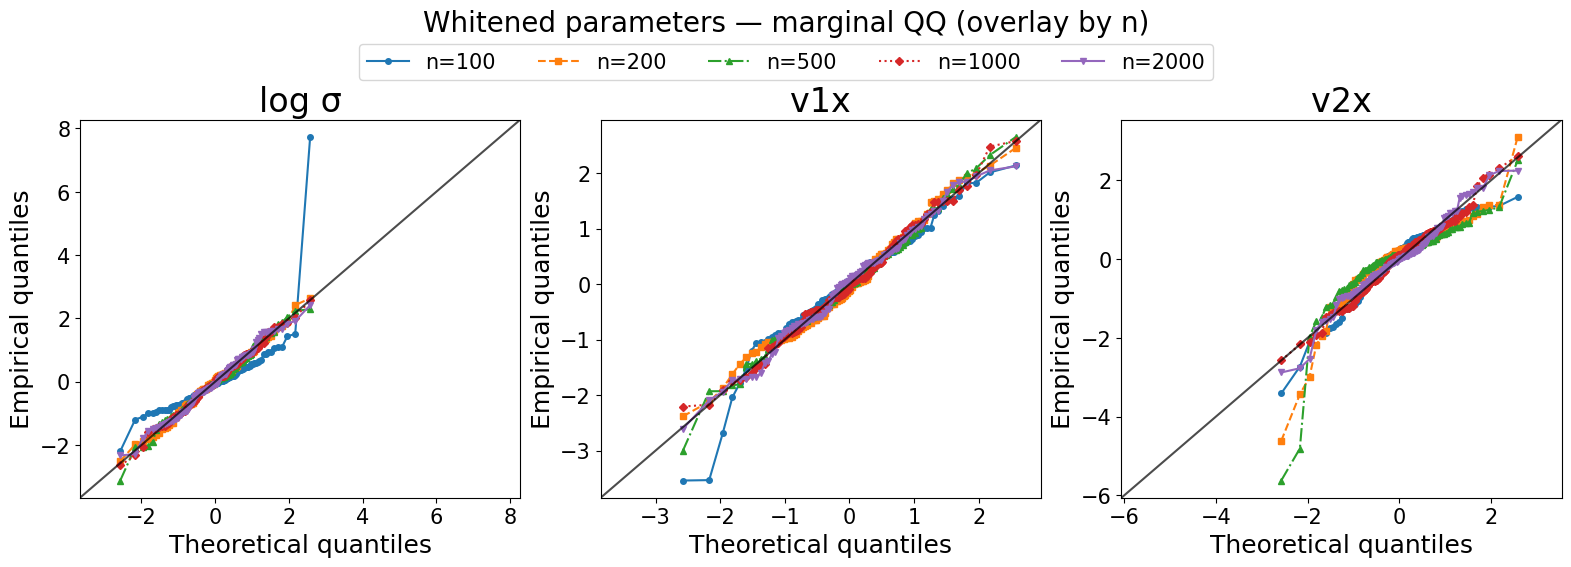

In [ ]:
# ===============================================
# FAST Asymptotic Normality Check (with plots)
# - Uses the SAME clustering algorithm as before:
#   EM-like (MM) loop + post-EM full NLL polish
# - Whitening via empirical covariance across replicates
# - Independent MH chain per (n, b) replicate (fixed seeds)
# - Diagnostic plots to verify normality
# ===============================================
import numpy as np
from numpy.linalg import cholesky, solve, LinAlgError, eigh
from scipy.optimize import minimize
from scipy.stats import kstest, norm
from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt
import time
import os

# ---------------------------
# True model (2D, c=2, m=2)
# ---------------------------
c = 2
m = 2.0
centers_true = np.array([[0.0, 0.0],
                         [3.5, 3.5]], dtype=float)
w_true = np.array([0.8, 0.2], dtype=float)
sigma_true = 2.0

# ---------------------------
# NOTE-aligned config
# ---------------------------
# Sample sizes and replicates (exactly as in the note)
n_list   = [100, 200, 500, 1000, 2000]
B_per_n  = 100

# MH chain (exactly as in the note)
MH_iters_max = 20000
MH_burn      = 0.2
prop_std     = 1.2

# GMM proposal (for NLL normalizer via IS; CRNs fixed per (b,n))
n_components_gmm = 3
M_IS = 5000

# plotting options
SAVE_PLOTS = False
OUTDIR_BASE = "normality_plots"

# ============================================================
# Helpers shared with earlier pipeline
# ============================================================
def _normalize_w(w, eps=1e-9):
    w = np.maximum(np.asarray(w, dtype=float), eps)
    return w / (w.sum() + eps)

def target_density_ccluster(x, sigma, centers, m, w, eps=1e-8):
    w = _normalize_w(w)
    diffs = x[:, None, :] - centers[None, :, :]
    dnorm = np.linalg.norm(diffs, axis=2) + eps
    dist_power = w[None, :] * (dnorm ** (-2.0 / (m - 1.0)))
    s = np.sum(dist_power, axis=1)
    denom = (s + eps) ** (m - 1.0)
    exponent = -1.0 / (sigma**2 * denom + eps)
    return np.exp(exponent)

def update_membership_c(data, centers, w, m, eps=1e-8):
    w = _normalize_w(w)
    diffs = data[:, None, :] - centers[None, :, :]
    dnorm = np.linalg.norm(diffs, axis=2) + eps
    dist_power = w[None, :] * (dnorm ** (-2.0 / (m - 1.0)))
    denom = np.sum(dist_power, axis=1, keepdims=True) + eps
    return dist_power / denom

def update_centroids_c(data, U, w, m, eps=1e-8):
    c = U.shape[1]
    d = data.shape[1]
    V = np.zeros((c, d), dtype=float)
    for j in range(c):
        ujm = (U[:, j] ** m)
        num = (ujm[:, None] * data).sum(axis=0)
        den = np.sum(ujm) + eps
        V[j] = num / den
    return V

def partial_negative_log_likelihood_full(params_vec, data, proposal_samples, proposal_weights, m, c, eps=1e-8):
    params_vec = np.asarray(params_vec, float)
    N, d = data.shape
    sigma = float(params_vec[0])
    centers = params_vec[1:1 + c*d].reshape((c, d))
    w = _normalize_w(params_vec[1 + c*d: 1 + c*d + c])

    diffs = data[:, None, :] - centers[None, :, :]
    dnorm = np.linalg.norm(diffs, axis=2) + eps
    dist_power = w[None, :] * (dnorm ** (-2.0 / (m - 1.0)))
    denom_data = (np.sum(dist_power, axis=1) + eps) ** (m - 1.0)
    energy = np.sum(1.0 / (sigma**2 * denom_data + eps))

    f_x = target_density_ccluster(proposal_samples, sigma, centers, m, w, eps=eps)
    ratio = f_x / (proposal_weights + 1e-12)
    Z_est = np.mean(ratio) + eps

    return N * np.log(Z_est) + energy

def pack_params(sigma, centers, w):
    return np.r_[float(sigma), centers.reshape(-1), _normalize_w(w)]

def unpack_params(params_vec, c, d):
    sigma = float(params_vec[0])
    centers = np.asarray(params_vec[1:1 + c*d], float).reshape((c, d))
    w = _normalize_w(np.asarray(params_vec[1 + c*d:1 + c*d + c], float))
    return sigma, centers, w

# ============================================================
# EM-like estimator + post-EM full NLL polish (SAME as before)
# ============================================================
def em_like_fuzzy_clustering_c_with_polish(
    data, proposal_samples, proposal_weights, m, c,
    initial_sigma=1.0, initial_centers=None, initial_w=None,
    max_iter_em=50, tol_em=1e-5, centroid_damping=0.9, random_state=42,
    do_polish=True, polish_max_iter=200, polish_tol=1e-6, verbose=False
):
    rng = np.random.RandomState(random_state)
    N, d = data.shape

    sigma = float(initial_sigma)
    if initial_centers is None:
        centers = data[rng.choice(N, c, replace=False)].copy()
    else:
        centers = np.asarray(initial_centers, float).reshape((c, d))
    if initial_w is None:
        w = np.ones(c) / c
    else:
        w = _normalize_w(initial_w)

    old_nll = None
    for it in range(max_iter_em):
        U = update_membership_c(data, centers, w, m)
        V_new = update_centroids_c(data, U, w, m)
        centers = centroid_damping * V_new + (1.0 - centroid_damping) * centers

        x0_sw = np.r_[sigma, w]
        bnds_sw = [(1e-5, 100.0)] + [(1e-6, 1.0)] * c
        def obj_sw(theta_sw):
            s = float(theta_sw[0])
            w_tmp = _normalize_w(theta_sw[1:])
            v = pack_params(s, centers, w_tmp)
            return partial_negative_log_likelihood_full(
                v, data, proposal_samples, proposal_weights, m, c
            )
        res_sw = minimize(obj_sw, x0_sw, method="L-BFGS-B", bounds=bnds_sw)
        if res_sw.success:
            sigma = float(res_sw.x[0])
            w = _normalize_w(res_sw.x[1:])

        full_vec = pack_params(sigma, centers, w)
        nll_new = partial_negative_log_likelihood_full(
            full_vec, data, proposal_samples, proposal_weights, m, c
        )
        if verbose:
            if old_nll is None:
                print(f"Iteration {it+1}/{max_iter_em}  NLL={nll_new:.6f}  Δ=—")
            else:
                print(f"Iteration {it+1}/{max_iter_em}  NLL={nll_new:.6f}  Δ={abs(old_nll-nll_new):.2e}")
        if (old_nll is not None) and (abs(old_nll - nll_new) < tol_em):
            old_nll = nll_new
            break
        old_nll = nll_new

    n_polish_iter = 0
    if do_polish:
        x0_full = pack_params(sigma, centers, w)
        bnds_full = [(1e-5, 100.0)] + [(None, None)] * (c * d) + [(1e-6, 1.0)] * c
        def obj_full(theta):
            return partial_negative_log_likelihood_full(
                theta, data, proposal_samples, proposal_weights, m, c
            )
        res_full = minimize(obj_full, x0_full, method="L-BFGS-B",
                            bounds=bnds_full, options=dict(maxiter=polish_max_iter, ftol=polish_tol))
        if res_full.success:
            n_polish_iter = int(res_full.nit)
            sigma, centers, w = unpack_params(res_full.x, c, d)
            final_nll = float(res_full.fun)
            if verbose:
                print(f"  [full NLL opt] status=OK iters={n_polish_iter} nll={final_nll:.6f}")
        else:
            final_nll = float(obj_full(x0_full))
            if verbose:
                print(f"  [full NLL opt] status=FAIL (kept EM params) nll={final_nll:.6f}")
    else:
        final_nll = float(old_nll)

    U_final = update_membership_c(data, centers, w, m)
    return {
        "c": c, "m": m, "sigma": float(sigma), "centers": centers, "w": w,
        "U": U_final, "NLL": float(final_nll),
        "polish_iters_used": int(n_polish_iter)
    }

# ============================================================
# MH sampler
# ============================================================
def mh_sample(initial_point, sigma, centers, m, w,
              iters=20000, prop_std=1.2, burn=0.2, seed=0):
    rng = np.random.RandomState(seed)
    d = centers.shape[1]
    samples = np.zeros((iters, d))
    samples[0] = initial_point
    accepted = 0
    curr_val = target_density_ccluster(samples[0][None, :], sigma, centers, m, w)[0]
    for i in range(1, iters):
        prop = samples[i-1] + rng.randn(d) * prop_std
        prop_val = target_density_ccluster(prop[None, :], sigma, centers, m, w)[0]
        alpha = min(1.0, prop_val / (curr_val + 1e-12))
        if rng.rand() < alpha:
            samples[i] = prop
            curr_val = prop_val
            accepted += 1
        else:
            samples[i] = samples[i-1]
    b = int(iters * burn)
    return samples[b:], accepted / (iters - 1)

# ============================================================
# GMM proposal (once per (replicate, n))
# ============================================================
def make_proposal(X, n_components, M, random_state=7):
    gmm = GaussianMixture(n_components=n_components, covariance_type='full', random_state=random_state)
    gmm.fit(X)
    propsamp, _ = gmm.sample(M)
    prop_pdf = np.exp(gmm.score_samples(propsamp))
    return propsamp, prop_pdf, gmm

# ============================================================
# Reparameterization (for normality plots only)
# ============================================================
def softmax(logits):
    m_ = np.max(logits)
    e = np.exp(logits - m_)
    return e / (np.sum(e) + 1e-12)

def free_from_weights(w, eps=1e-12):
    w = np.asarray(w, float); w = w / (w.sum() + eps)
    return np.log(np.maximum(w[:-1], eps) / max(w[-1], eps))

def weights_from_free(a, eps_floor=1e-3):
    a = np.asarray(a, float)
    logits = np.r_[a, 0.0]
    w_raw = softmax(logits)
    c_ = w_raw.size
    return eps_floor + (1.0 - c_*eps_floor) * w_raw

def pack_free_params(s_log, centers, a):
    return np.r_[s_log, centers.ravel(), a]

def unpack_free_params(p, c):
    s_log = p[0]
    sigma = np.exp(s_log)
    centers = p[1:1+2*c].reshape((c,2))
    a = p[1+2*c:]
    w = weights_from_free(a)
    return sigma, centers, w

# ============================================================
# Label alignment (c=2)
# ============================================================
def align_labels(theta_hat, theta_true):
    sigma_h, Vh, wh = theta_hat
    _, Vt, _ = theta_true
    d00 = np.linalg.norm(Vh[0]-Vt[0]); d11 = np.linalg.norm(Vh[1]-Vt[1])
    d01 = np.linalg.norm(Vh[0]-Vt[1]); d10 = np.linalg.norm(Vh[1]-Vt[0])
    if d00 + d11 <= d01 + d10:
        return sigma_h, Vh.copy(), wh.copy()
    else:
        return sigma_h, Vh[::-1].copy(), wh[::-1].copy()

# ============================================================
# Plot helpers
# ============================================================
def ensure_outdir(path):
    if path and not os.path.exists(path):
        os.makedirs(path, exist_ok=True)

import matplotlib.ticker as mtick
def _nice_markers():
    return ['o', 's', 'D', '^', 'v', 'P']
def _nice_linestyles():
    return ['-', '--', '-.', ':', (0,(1,1)), (0,(5,1,1,1))]

def make_overlay_marginal_qq(diag_by_n, coord_names, coord_ids=(0,1,3),
                             title="Whitened parameters — marginal QQ (overlay by n)",
                             outpath=None):
    ns = list(diag_by_n.keys())
    K = len(coord_ids)
    fig, axes = plt.subplots(1, K, figsize=(5.2*K, 4.8), constrained_layout=True)
    markers = ['o', 's', '^', 'D', 'v', '*']
    linestyles = ['-', '--', '-.', ':']

    for k, cid in enumerate(coord_ids):
        ax = axes[k] if K > 1 else axes
        for i, n in enumerate(ns):
            Y = diag_by_n[n]['Y_emp']
            z = Y[:, cid]
            z = (z - z.mean()) / (z.std(ddof=1) + 1e-12)
            B = len(z)
            q = norm.ppf((np.arange(1, B+1) - 0.5) / B)
            ax.plot(q, np.sort(z),
                    marker=markers[i % len(markers)], markersize=4.0, linewidth=1.5,
                    linestyle=linestyles[i % len(linestyles)],
                    label=f"n={n}")
        # y=x
        lo, hi = ax.get_xlim(); lo2, hi2 = ax.get_ylim()
        lo = min(lo, lo2); hi = max(hi, hi2)
        ax.plot([lo, hi], [lo, hi], 'k-', linewidth=1.5, alpha=0.7)
        ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
        ax.set_xlabel("Theoretical quantiles", fontsize=18)
        ax.set_ylabel("Empirical quantiles", fontsize=18)
        clean_title = coord_names[cid].replace("_", "")
        ax.set_title(clean_title, fontsize=24)
        ax.tick_params(axis='both', which='major', labelsize=15)

    handles, labels = axes[-1].get_legend_handles_labels() if K > 1 else axes.get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center',
               ncol=min(len(ns), 5), fontsize=15,
               bbox_to_anchor=(0.5, 1.1))
    fig.suptitle(title, y=1.15, fontsize=20)

    if outpath:
        fig.savefig(outpath, dpi=900, bbox_inches="tight")
        plt.close(fig)
    else:
        plt.show()

# ============================================================
# Estimation wrapper (unchanged algorithm)
# ============================================================
def em_then_full_nll_mle(data, m, c, propsamp, prop_pdf,
                         init_sigma=1.0, init_centers=None, init_w=None,
                         em_iters=50, em_tol=1e-5, centroid_damping=0.9,
                         polish_max_iter=200, polish_tol=1e-6, random_state=0, verbose=False):
    return em_like_fuzzy_clustering_c_with_polish(
        data=data,
        proposal_samples=propsamp,
        proposal_weights=prop_pdf,
        m=m, c=c,
        initial_sigma=init_sigma,
        initial_centers=init_centers,
        initial_w=init_w,
        max_iter_em=em_iters,
        tol_em=em_tol,
        centroid_damping=centroid_damping,
        random_state=random_state,
        do_polish=True,
        polish_max_iter=polish_max_iter,
        polish_tol=polish_tol,
        verbose=verbose
    )

# ============================================================
# FAST driver with plots (now: independent MH per (n,b), fixed seeds)
# ============================================================
def run_fast_normality_with_plots_compact():
    # fixed seeds per (n,b) give reproducible, independent datasets
    coord_names = ["log σ", "v1_x", "v1_y", "v2_x", "v2_y", "weight logit a1"]

    s_true = np.log(sigma_true)
    from_logits = free_from_weights(w_true)
    p_true = np.r_[s_true, centers_true.ravel(), from_logits]

    diag_by_n = {}
    all_results = {}

    for n in n_list:
        print(f"\n===== n = {n} =====")
        start = time.time()
        Ps = []
        ok = 0

        for b in range(B_per_n):
            # --- independent MH chain for this (n, b), fixed seed ---
            seed_chain = 77_000 + 10_000 * n + b
            X_chain, acc = mh_sample(np.array([0., 0.]), sigma_true, centers_true, m, w_true,
                                     iters=MH_iters_max, prop_std=prop_std, burn=MH_burn,
                                     seed=seed_chain)
            if X_chain.shape[0] < n:
                continue
            X = X_chain[:n]

            # proposal (CRNs fixed per (n,b))
            propsamp, prop_pdf, _ = make_proposal(X, n_components_gmm, M_IS, random_state=7 + b)

            # gentle init near truth
            rng = np.random.RandomState(999 + 10_000 * n + b)
            init_centers = centers_true + 0.2 * rng.randn(*centers_true.shape)
            init_sigma    = max(1e-2, sigma_true + 0.05 * rng.randn())
            init_w        = _normalize_w(w_true + 0.02 * rng.randn(c))

            fit = em_then_full_nll_mle(
                data=X, m=m, c=c, propsamp=propsamp, prop_pdf=prop_pdf,
                init_sigma=init_sigma, init_centers=init_centers, init_w=init_w,
                em_iters=50, em_tol=1e-5, centroid_damping=0.9,
                polish_max_iter=200, polish_tol=1e-6,
                random_state=2025 + 10_000 * n + b, verbose=False
            )
            if not np.isfinite(fit["NLL"]):
                continue

            # align & pack to free params for diagnostics
            theta_hat = (fit["sigma"], fit["centers"], fit["w"])
            sigma_h, centers_h, w_h = align_labels(theta_hat, (sigma_true, centers_true, w_true))
            s_h = np.log(sigma_h)
            a_h = free_from_weights(w_h)
            p_hat = np.r_[s_h, centers_h.ravel(), a_h]
            Ps.append(p_hat); ok += 1

        if ok == 0:
            print("No successful replicates for this n.")
            continue

        Ps = np.vstack(Ps)
        D = (Ps - p_true[None, :])

        # whitening
        Sigma_emp = np.cov(D.T, bias=False)
        Sigma_emp = 0.5 * (Sigma_emp + Sigma_emp.T)
        try:
            L = cholesky(Sigma_emp)
        except LinAlgError:
            vals, vecs = eigh(Sigma_emp)
            vals = np.maximum(vals, 1e-8)
            Sigma_emp = (vecs * vals) @ vecs.T
            L = cholesky(Sigma_emp)

        Y = np.array([solve(L, dvec) for dvec in D])
        mah2 = np.sum(Y**2, axis=1)

        ks_pvec = []
        for j in range(Ps.shape[1]):
            z = Y[:, j]
            z = (z - z.mean())/(z.std(ddof=1) + 1e-12)
            ks_pvec.append(kstest(z, 'norm').pvalue)

        print(f"Successful replicates: {ok}/{B_per_n}   Wall time: {time.time()-start:0.1f}s")

        diag_by_n[int(n)] = {'Y_emp': Y, 'mah2': mah2, 'ok': ok, 'ks_pvec': np.array(ks_pvec)}
        all_results[n] = mah2

    return all_results, diag_by_n, coord_names

# ============================================================
# Example run + simple QQ plot
# ============================================================
if __name__ == "__main__":
    results, diag, coord_names = run_fast_normality_with_plots_compact()
    make_overlay_marginal_qq(diag, coord_names, coord_ids=(0,1,3),
                             title="Whitened parameters — marginal QQ (overlay by n)")
